In [1]:
# =========================================================
# SETUP CELL — REPLACES the old one. Safe to run every session.
# Uses force_remount=True — clears stale mount points, always works.
# =========================================================
from google.colab import drive
import os, shutil

MOUNT_POINT = '/content/drive'

# --- Step 1: If the mount point exists but isn't a real mount, clean it ---
if os.path.exists(MOUNT_POINT) and not os.path.ismount(MOUNT_POINT):
    print("🧹 Cleaning stale mount point...")
    shutil.rmtree(MOUNT_POINT)
    os.makedirs(MOUNT_POINT)

# --- Step 2: Force remount (this always works, avoids the "already contains files" error) ---
drive.mount(MOUNT_POINT, force_remount=True)

# --- Step 3: VERIFY the mount actually succeeded ---
if not os.path.isdir('/content/drive/MyDrive'):
    raise RuntimeError("❌ Drive mount failed — cannot see MyDrive. Stop and fix before continuing.")

print("✅ Drive mounted and MyDrive is visible.")

# --- Step 4: Project paths ---
PROJECT_ROOT = "/content/drive/MyDrive/olist-retention-project"
RAW          = os.path.join(PROJECT_ROOT, "data/raw")

# --- Step 5: Create the folder structure (idempotent) ---
folders = [
    "data/raw", "data/processed", "notebooks",
    "sql", "outputs/figures", "outputs/reports", "docs",
]
for f in folders:
    os.makedirs(os.path.join(PROJECT_ROOT, f), exist_ok=True)

print(f"✅ Folders ready at: {PROJECT_ROOT}")

# --- Step 6: CRITICAL — show what's actually IN raw/ right now ---
print(f"\n📄 Contents of data/raw/ RIGHT NOW:")
raw_contents = os.listdir(RAW)
if not raw_contents:
    print("   ⚠️  EMPTY — the CSVs are not here.")
    print("      → Check Google Drive in your browser: MyDrive/olist-retention-project/data/raw/")
    print("      → If CSVs are missing there, re-upload them.")
else:
    for f in sorted(raw_contents):
        size_mb = os.path.getsize(os.path.join(RAW, f)) / (1024*1024)
        print(f"   {f}  ({size_mb:.1f} MB)")

Mounted at /content/drive
✅ Drive mounted and MyDrive is visible.
✅ Folders ready at: /content/drive/MyDrive/olist-retention-project

📄 Contents of data/raw/ RIGHT NOW:
   olist_customers_dataset.csv  (8.6 MB)
   olist_geolocation_dataset.csv  (58.4 MB)
   olist_order_items_dataset.csv  (14.7 MB)
   olist_order_payments_dataset.csv  (5.5 MB)
   olist_order_reviews_dataset.csv  (13.8 MB)
   olist_orders_dataset.csv  (16.8 MB)
   olist_products_dataset.csv  (2.3 MB)
   olist_sellers_dataset.csv  (0.2 MB)
   product_category_name_translation.csv  (0.0 MB)


In [2]:
# =========================================================
# FIND YOUR CSVs — run this to see what's in raw/ and where
# =========================================================
import os

PROJECT_ROOT = "/content/drive/MyDrive/olist-retention-project"
RAW = os.path.join(PROJECT_ROOT, "data/raw")

print("Looking inside:", RAW)
print("=" * 60)

if not os.path.exists(RAW):
    print("❌ raw/ folder doesn't exist. Did Cell 1 (setup) run?")
else:
    for item in os.listdir(RAW):
        full = os.path.join(RAW, item)
        if os.path.isdir(full):
            print(f"📁 {item}/  (folder)")
            for sub in os.listdir(full):
                print(f"     └── {sub}")
        else:
            size_mb = os.path.getsize(full) / (1024 * 1024)
            print(f"📄 {item}  ({size_mb:.1f} MB)")

Looking inside: /content/drive/MyDrive/olist-retention-project/data/raw
📄 olist_customers_dataset.csv  (8.6 MB)
📄 olist_geolocation_dataset.csv  (58.4 MB)
📄 olist_order_items_dataset.csv  (14.7 MB)
📄 olist_order_payments_dataset.csv  (5.5 MB)
📄 olist_orders_dataset.csv  (16.8 MB)
📄 olist_order_reviews_dataset.csv  (13.8 MB)
📄 olist_products_dataset.csv  (2.3 MB)
📄 olist_sellers_dataset.csv  (0.2 MB)
📄 product_category_name_translation.csv  (0.0 MB)


In [3]:
# =========================================================
# UPDATE DECISIONS.md — pivot to Delivery Performance
# =========================================================
import os

PROJECT_ROOT = "/content/drive/MyDrive/olist-retention-project"
decisions_path = os.path.join(PROJECT_ROOT, "docs/DECISIONS.md")

decisions_content = """# Decisions log

## 0. Project Overview

**Project:** Olist Delivery Performance & Customer Satisfaction
**Domain:** Brazilian e-commerce marketplace
**Client:** Simulated case study for portfolio (no real client)
**Intended user:** Olist's operations / logistics team
**Business problem:** Late deliveries damage customer satisfaction. We need to
find where the fulfillment pipeline fails, quantify the cost in review scores,
and identify the worst-performing regions, categories, and sellers.

**Main questions:**
1. What is the overall on-time delivery rate?
2. Which states/regions have the worst delivery performance?
3. Which product categories suffer the longest delivery times?
4. How much does a late delivery cost in review score?
5. Which stage of the pipeline causes the most delay?

**Deliverables:**
- Cleaned CSV + SQLite database
- SQL queries (sql/ folder)
- Excel workbook (KPI overview, detail, data-quality log, definitions)
- Plotly HTML dashboard (KPI cards + bar/line/pie charts)

**Definition of done:**
- Every headline KPI computed in SQL AND Pandas, reconciled
- Every cleaning decision logged
- README + DECISIONS.md complete
- Notebook reruns from raw CSVs to final outputs

**Optional stages:**
- Step 7 (Outliers): YES - delivery times likely have extremes
- Step 8 (Derived fields): YES - delivery_days, is_late, stage_durations
- Step 13 (Automation): NO - one-time portfolio piece

---

## 1. Data dictionary
(to be filled in Step 2)

## 2. KPI definitions

### Order population
The analysis universe = orders with `order_status = 'delivered'`
AND `order_delivered_customer_date IS NOT NULL`.
Reason: undelivered orders have no outcome to measure.

### Analysis window
- purchase date: 2017-01-01 to 2018-08-31
- Reason: Sep-Dec 2016 has <400 orders total; monthly trends would be noise.

| KPI | Formula | Date field | Exclusions | Grain |
|---|---|---|---|---|
| On-Time Delivery Rate | on-time / delivered | delivered vs estimated | non-delivered, NULL | order |
| Avg Lateness (Late) | avg(delivered - estimated) where late | delivered_customer_date | on-time orders | order |
| Avg Days to Deliver | avg(delivered - purchased) | order_purchase_timestamp | non-delivered | order |
| Review: Late vs On-Time | avg review_score split by lateness | review_creation_date | no review | order |
| Stage Durations | diff between 5 timestamps | all timestamps | missing timestamps | order |
| Worst Sellers | bottom 10% on-time, min 20 orders | delivered date | <20 orders | seller |

## 3. Table scope decision

**In scope:** orders, order_reviews, customers, order_items, products,
              category translation, sellers
**Out of scope:** order_payments (payment method does not affect delivery),
                  geolocation (redundant - customers table has state)

## 4. Cleaning log
(to be filled in Step 6)

## 5. Client answers and assumptions
(all answers are assumptions - simulated project)

## 6. Skipped steps
- Skipped use of order_payments table: not relevant to delivery timing
- Skipped use of geolocation table: customers table already has state/city

## 7. Limitations
(to be filled in Step 14)
"""

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(decisions_content)

print("✅ DECISIONS.md updated:", decisions_path)
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ DECISIONS.md updated: /content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md
   Size: 3149 bytes


In [4]:
# =========================================================
# FLATTEN — move CSVs out of RETAIL SALES DATASET/ into data/raw/
# =========================================================
import os, shutil

RAW = "/content/drive/MyDrive/olist-retention-project/data/raw"
NESTED = os.path.join(RAW, "RETAIL SALES DATASET")

if os.path.exists(NESTED):
    for f in os.listdir(NESTED):
        shutil.move(os.path.join(NESTED, f), os.path.join(RAW, f))
    os.rmdir(NESTED)
    print("✅ Flattened — folder removed")
else:
    print("ℹ️  Folder already flat or missing")

print("\n📄 data/raw/ now contains:")
for f in sorted(os.listdir(RAW)):
    size_mb = os.path.getsize(os.path.join(RAW, f)) / (1024 * 1024)
    print(f"   {f}  ({size_mb:.1f} MB)")

ℹ️  Folder already flat or missing

📄 data/raw/ now contains:
   olist_customers_dataset.csv  (8.6 MB)
   olist_geolocation_dataset.csv  (58.4 MB)
   olist_order_items_dataset.csv  (14.7 MB)
   olist_order_payments_dataset.csv  (5.5 MB)
   olist_order_reviews_dataset.csv  (13.8 MB)
   olist_orders_dataset.csv  (16.8 MB)
   olist_products_dataset.csv  (2.3 MB)
   olist_sellers_dataset.csv  (0.2 MB)
   product_category_name_translation.csv  (0.0 MB)


In [5]:
# =========================================================
# STEP 2 — INVENTORY ALL 9 TABLES
# Prints: shape, columns, nulls, unique counts, sample rows
# =========================================================
import os
import pandas as pd

RAW = "/content/drive/MyDrive/olist-retention-project/data/raw"
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 220)
pd.set_option('display.max_colwidth', 40)

CSVS = {
    "olist_customers_dataset.csv":           "customers",
    "olist_geolocation_dataset.csv":         "geolocation",
    "olist_order_items_dataset.csv":         "order_items",
    "olist_order_payments_dataset.csv":      "order_payments",
    "olist_order_reviews_dataset.csv":       "order_reviews",
    "olist_orders_dataset.csv":              "orders",
    "olist_products_dataset.csv":            "products",
    "olist_sellers_dataset.csv":             "sellers",
    "product_category_name_translation.csv": "category_translation",
}

# Read everything as strings first (safer inventory — we don't want pandas
# guessing types yet). Then we'll inspect.
frames = {}

for csv_name, label in CSVS.items():
    path = os.path.join(RAW, csv_name)
    df = pd.read_csv(path, dtype=str, keep_default_na=False, na_values=[""])
    frames[label] = df

    print("\n" + "=" * 75)
    print(f"📦 {label.upper()}  ({csv_name})")
    print("=" * 75)
    print(f"Shape: {df.shape[0]:,} rows × {df.shape[1]} columns\n")

    print(f"{'column':<42}{'nulls':>10}{'null %':>10}{'unique':>12}")
    print("-" * 75)
    for col in df.columns:
        n_null = df[col].isna().sum()
        n_unique = df[col].nunique()
        pct = (n_null / len(df) * 100) if len(df) else 0
        print(f"{col:<42}{n_null:>10,}{pct:>9.1f}%{n_unique:>12,}")

    print("\nFirst 2 rows:")
    print(df.head(2).to_string())


📦 CUSTOMERS  (olist_customers_dataset.csv)
Shape: 99,441 rows × 5 columns

column                                         nulls    null %      unique
---------------------------------------------------------------------------
customer_id                                        0      0.0%      99,441
customer_unique_id                                 0      0.0%      96,096
customer_zip_code_prefix                           0      0.0%      14,994
customer_city                                      0      0.0%       4,119
customer_state                                     0      0.0%          27

First 2 rows:
                        customer_id                customer_unique_id customer_zip_code_prefix          customer_city customer_state
0  06b8999e2fba1a1fbc88172c00ba8bc7  861eff4711a542e4b93843c6dd7febb0                    14409                 franca             SP
1  18955e83d337fd6b2def6b18a428ac77  290c77bc529b7ac935b93aa66c333dc3                    09790  sao bernardo do campo

In [6]:
# =========================================================
# STEP 2b — KEY UNIQUENESS + DATE COVERAGE
# =========================================================
import pandas as pd

print("🔑 KEY UNIQUENESS CHECKS")
print("=" * 70)

def check_key(df, cols, label):
    if isinstance(cols, str):
        cols = [cols]
    n_rows = len(df)
    n_unique = df.groupby(cols, dropna=False).size().shape[0] if len(cols) > 1 else df[cols[0]].nunique()
    if n_unique == n_rows:
        verdict = "✅ UNIQUE — good primary key"
    else:
        verdict = f"⚠️  {n_rows - n_unique:,} duplicates"
    print(f"{label:<50} {verdict}")

check_key(frames['orders'],                'order_id',                          'orders.order_id')
check_key(frames['customers'],             'customer_id',                       'customers.customer_id')
check_key(frames['customers'],             'customer_unique_id',                'customers.customer_unique_id  ← repeat key')
check_key(frames['order_items'],           ['order_id', 'order_item_id'],       'order_items.(order_id, order_item_id)')
check_key(frames['order_reviews'],         'review_id',                         'order_reviews.review_id')
check_key(frames['order_reviews'],         ['review_id', 'order_id'],           'order_reviews.(review_id, order_id)')
check_key(frames['order_payments'],        ['order_id', 'payment_sequential'],  'order_payments.(order_id, payment_sequential)')
check_key(frames['products'],              'product_id',                        'products.product_id')
check_key(frames['sellers'],               'seller_id',                         'sellers.seller_id')
check_key(frames['category_translation'],  'product_category_name',             'category_translation.product_category_name')

print("\n📅 ORDER DATE COVERAGE")
print("=" * 70)

orders = frames['orders']
date_cols = [
    'order_purchase_timestamp',
    'order_approved_at',
    'order_delivered_carrier_date',
    'order_delivered_customer_date',
    'order_estimated_delivery_date',
]
for col in date_cols:
    s = pd.to_datetime(orders[col], errors='coerce')
    n_null = s.isna().sum()
    print(f"{col:<35} min: {str(s.min())[:19]:<20} max: {str(s.max())[:19]:<20} nulls: {n_null:,}")

print("\n📊 ORDER STATUS DISTRIBUTION")
print("=" * 70)
print(orders['order_status'].value_counts().to_string())

print("\n📊 REVIEW SCORE DISTRIBUTION")
print("=" * 70)
print(frames['order_reviews']['review_score'].value_counts().sort_index().to_string())

🔑 KEY UNIQUENESS CHECKS
orders.order_id                                    ✅ UNIQUE — good primary key
customers.customer_id                              ✅ UNIQUE — good primary key
customers.customer_unique_id  ← repeat key         ⚠️  3,345 duplicates
order_items.(order_id, order_item_id)              ✅ UNIQUE — good primary key
order_reviews.review_id                            ⚠️  814 duplicates
order_reviews.(review_id, order_id)                ✅ UNIQUE — good primary key
order_payments.(order_id, payment_sequential)      ✅ UNIQUE — good primary key
products.product_id                                ✅ UNIQUE — good primary key
sellers.seller_id                                  ✅ UNIQUE — good primary key
category_translation.product_category_name         ✅ UNIQUE — good primary key

📅 ORDER DATE COVERAGE
order_purchase_timestamp            min: 2016-09-04 21:15:19  max: 2018-10-17 17:30:18  nulls: 0
order_approved_at                   min: 2016-09-15 12:16:38  max: 2018-09-03 17:4

In [7]:
# =========================================================
# UPDATE DECISIONS.md — Add Data Dictionary (Step 2 output)
# =========================================================
import os

decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

# Read existing content
with open(decisions_path, "r", encoding="utf-8") as f:
    existing = f.read()

# Replace the placeholder section
data_dict = """## 1. Data dictionary

### Tables in scope

| Table | Grain (what one row means) | Primary key | Rows |
|---|---|---|---|
| orders | one order | order_id | 99,441 |
| customers | one customer identity per order | customer_id | 99,441 |
| order_items | one product line within an order | (order_id, order_item_id) | 112,650 |
| order_reviews | one review per (review_id, order_id) | (review_id, order_id) | 99,224 |
| products | one product | product_id | 32,951 |
| sellers | one seller | seller_id | 3,095 |
| category_translation | one PT->EN category mapping | product_category_name | 71 |

### Tables out of scope (documented reason)

| Table | Reason |
|---|---|
| order_payments | Payment method does not affect delivery timing |
| geolocation | 1M rows, 53 per zip prefix; customers.customer_state already answers geographic questions |

### Key columns in `orders`

| Column | Meaning | Notes |
|---|---|---|
| order_id | order identifier | unique, primary key |
| customer_id | per-order customer key | FK to customers |
| order_status | one of 8 statuses | delivered = 96,478 (97%) |
| order_purchase_timestamp | when order was placed | 0 nulls |
| order_approved_at | payment approved | 160 nulls (~canceled orders) |
| order_delivered_carrier_date | handed to carrier | 1,783 nulls |
| order_delivered_customer_date | delivered to customer | 2,965 nulls (= non-delivered orders) |
| order_estimated_delivery_date | promised delivery date | 0 nulls, always set at checkout |

### Critical warning — customer keys

**customers.customer_id** = unique per order (99,441 unique values).
**customers.customer_unique_id** = persistent identity across orders (96,096 unique values; 3,345 duplicates).

For any per-customer aggregation, use `customer_unique_id`. Using `customer_id` treats every purchase as a new customer.

### Known issues (to be resolved in Step 4/6)

| Issue | Count | Where |
|---|---|---|
| review_id duplicates | 814 | order_reviews |
| order_id duplicates in reviews | 551 | order_reviews |
| orders without line items | 775 | orders vs order_items |
| product_category_name nulls | 610 | products |
| product weight/dimensions nulls | 2 | products |
| review_comment_title nulls | 87,656 | order_reviews (optional field) |
| review_comment_message nulls | 58,247 | order_reviews (optional field) |

### Date coverage

- order_purchase_timestamp: 2016-09-04 -> 2018-10-17
- Analysis window chosen: 2017-01-01 -> 2018-08-31
  Reason: Sep-Dec 2016 has <400 orders total; monthly trends would be noise.
  Oct 2018 has minimal orders and incomplete delivery data.

### Order status distribution

| Status | Count |
|---|---|
| delivered | 96,478 |
| shipped | 1,107 |
| canceled | 625 |
| unavailable | 609 |
| invoiced | 314 |
| processing | 301 |
| created | 5 |
| approved | 2 |

### Review score distribution

| Score | Count | % |
|---|---|---|
| 1 | 11,424 | 11.5% |
| 2 | 3,151 | 3.2% |
| 3 | 8,179 | 8.2% |
| 4 | 19,142 | 19.3% |
| 5 | 57,328 | 57.8% |

Note: bimodal (U-shaped), not normal.
"""

# Replace the placeholder section
existing = existing.replace("## 1. Data dictionary\n(to be filled in Step 2)\n", data_dict)

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(existing)

print("✅ Data dictionary added to DECISIONS.md")
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ Data dictionary added to DECISIONS.md
   Size: 6128 bytes


In [8]:
# =========================================================
# APPEND — Pipeline stage definitions to DECISIONS.md
# =========================================================
import os

decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

stage_section = """
### Pipeline stage definitions (Step 2 output)

Four measurable stages between the 5 order timestamps:

| Stage | Formula | What it measures |
|---|---|---|
| 1. Approval | approved_at - purchase_timestamp | Payment confirmation time |
| 2. Handoff to carrier | delivered_carrier_date - approved_at | Seller packing + dispatch time |
| 3. Last-mile delivery | delivered_customer_date - delivered_carrier_date | Carrier delivery time |
| 4. End-to-end | delivered_customer_date - purchase_timestamp | Total fulfillment time |

The 5th timestamp (order_estimated_delivery_date) is a PROMISE made at
checkout, not a pipeline stage. It is used as a benchmark:
- On-time delivery = delivered_customer_date <= estimated_delivery_date
- Lateness (days) = delivered_customer_date - estimated_delivery_date
"""

# Append after the review score distribution section
content = content.rstrip() + "\n" + stage_section

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)

print("✅ Pipeline stages added to DECISIONS.md")

✅ Pipeline stages added to DECISIONS.md


In [9]:
# =========================================================
# STEP 3 — SAFE LOADING WITH EXPLICIT TYPES
# Loads the 7 in-scope tables with correct dtypes.
# Raw files are NEVER modified — this is read-only.
# =========================================================
import os
import pandas as pd

RAW = "/content/drive/MyDrive/olist-retention-project/data/raw"

# ---- The 7 tables we need, with their explicit dtypes ----
# Anything not listed defaults to string (safe fallback).
TABLES = {
    "olist_orders_dataset.csv": {
        "name": "orders",
        "str_cols": ["order_id", "customer_id", "order_status"],
        "date_cols": [
            "order_purchase_timestamp",
            "order_approved_at",
            "order_delivered_carrier_date",
            "order_delivered_customer_date",
            "order_estimated_delivery_date",
        ],
    },
    "olist_customers_dataset.csv": {
        "name": "customers",
        "str_cols": ["customer_id", "customer_unique_id",
                     "customer_zip_code_prefix", "customer_city", "customer_state"],
        "date_cols": [],
    },
    "olist_order_items_dataset.csv": {
        "name": "order_items",
        "str_cols": ["order_id", "product_id", "seller_id"],
        "date_cols": ["shipping_limit_date"],
        "num_cols": ["order_item_id", "price", "freight_value"],
    },
    "olist_order_reviews_dataset.csv": {
        "name": "order_reviews",
        "str_cols": ["review_id", "order_id"],
        "date_cols": ["review_creation_date", "review_answer_timestamp"],
        "num_cols": ["review_score"],
    },
    "olist_products_dataset.csv": {
        "name": "products",
        "str_cols": ["product_id", "product_category_name"],
        "date_cols": [],
        "num_cols": [
            "product_name_lenght", "product_description_lenght",
            "product_photos_qty", "product_weight_g",
            "product_length_cm", "product_height_cm", "product_width_cm",
        ],
    },
    "olist_sellers_dataset.csv": {
        "name": "sellers",
        "str_cols": ["seller_id", "seller_zip_code_prefix",
                     "seller_city", "seller_state"],
        "date_cols": [],
    },
    "product_category_name_translation.csv": {
        "name": "category_translation",
        "str_cols": ["product_category_name", "product_category_name_english"],
        "date_cols": [],
    },
}


def load_raw():
    """Load the 7 in-scope Olist tables with explicit, safe dtypes.
    Returns a dict of DataFrames keyed by short name."""
    frames = {}

    for filename, spec in TABLES.items():
        path = os.path.join(RAW, filename)
        if not os.path.exists(path):
            raise FileNotFoundError(f"Missing file: {path}")

        # Build the dtype dict for pandas
        # Everything not explicitly numeric/date gets loaded as string
        dtype_map = {}
        for c in spec.get("str_cols", []):
            dtype_map[c] = "string"     # pandas nullable string
        for c in spec.get("num_cols", []):
            dtype_map[c] = "float64"    # we'll cast to int later if needed

        df = pd.read_csv(path, dtype=dtype_map)

        # Parse date columns explicitly — count failures rather than silently coerce
        for c in spec.get("date_cols", []):
            parsed = pd.to_datetime(df[c], errors="coerce")
            n_failed = parsed.isna().sum() - df[c].isna().sum()
            if n_failed > 0:
                print(f"  ⚠️  {spec['name']}.{c}: {n_failed} parse failures")
            df[c] = parsed

        frames[spec["name"]] = df
        print(f"  ✅ {spec['name']:<22} {df.shape[0]:>8,} rows  ×  {df.shape[1]:>2} cols")

    return frames


print("📥 Loading 7 tables from data/raw/ (read-only, dtypes explicit)\n")
frames = load_raw()
print(f"\n✅ Loaded {len(frames)} tables into memory.")
print("   Raw files in data/raw/ are UNCHANGED.")

📥 Loading 7 tables from data/raw/ (read-only, dtypes explicit)

  ✅ orders                   99,441 rows  ×   8 cols
  ✅ customers                99,441 rows  ×   5 cols
  ✅ order_items             112,650 rows  ×   7 cols
  ✅ order_reviews            99,224 rows  ×   7 cols
  ✅ products                 32,951 rows  ×   9 cols
  ✅ sellers                   3,095 rows  ×   4 cols
  ✅ category_translation         71 rows  ×   2 cols

✅ Loaded 7 tables into memory.
   Raw files in data/raw/ are UNCHANGED.


In [10]:
# Spot-check the dtypes are right
print(frames['orders'].dtypes)
print(frames['orders']['order_purchase_timestamp'].min())
print(frames['order_items']['price'].sum())

order_id                         string[python]
customer_id                      string[python]
order_status                     string[python]
order_purchase_timestamp         datetime64[ns]
order_approved_at                datetime64[ns]
order_delivered_carrier_date     datetime64[ns]
order_delivered_customer_date    datetime64[ns]
order_estimated_delivery_date    datetime64[ns]
dtype: object
2016-09-04 21:15:19
13591643.700000003


In [11]:
# =========================================================
# STEP 4A — VALIDITY AND SEQUENCE CHECKS
# =========================================================
import pandas as pd
import numpy as np

o  = frames['orders']
i  = frames['order_items']
r  = frames['order_reviews']
p  = frames['products']
c  = frames['customers']
s  = frames['sellers']

issues = []

def log(issue, mask, df):
    n = int(mask.sum())
    examples = df.loc[mask].head(3).index.tolist() if n else []
    issues.append({"issue": issue, "rows": n, "examples": examples})
    flag = "⚠️ " if n > 0 else "✅ "
    print(f"{flag}{issue:<55} {n:>8,}")

print("=" * 78)
print("STEP 4A — VALIDITY AND SEQUENCE CHECKS")
print("=" * 78)

# ---- Orders: impossible sequences ----
print("\n📌 Orders — timestamp sequence violations")
log("approved_at < purchase_timestamp",
    (o['order_approved_at'] < o['order_purchase_timestamp']).fillna(False), o)
log("carrier_date < approved_at",
    (o['order_delivered_carrier_date'] < o['order_approved_at']).fillna(False), o)
log("delivered_customer_date < delivered_carrier_date",
    (o['order_delivered_customer_date'] < o['order_delivered_carrier_date']).fillna(False), o)
log("estimated_date < purchase_timestamp",
    (o['order_estimated_delivery_date'] < o['order_purchase_timestamp']).fillna(False), o)

# ---- Orders: contradictions ----
print("\n📌 Orders — status vs date contradictions")
log("status=delivered but no delivery date",
    (o['order_status'] == 'delivered') & o['order_delivered_customer_date'].isna(), o)
log("status=delivered but no carrier date",
    (o['order_status'] == 'delivered') & o['order_delivered_carrier_date'].isna(), o)
log("status=canceled but delivery date exists",
    (o['order_status'] == 'canceled') & o['order_delivered_customer_date'].notna(), o)

# ---- Order items: bad numbers ----
print("\n📌 Order items — numeric range violations")
log("negative price", i['price'] < 0, i)
log("zero price", i['price'] == 0, i)
log("negative freight_value", i['freight_value'] < 0, i)

# ---- Reviews: bad scores ----
print("\n📌 Reviews — score range violations")
log("review_score outside 1-5", ~r['review_score'].isin([1, 2, 3, 4, 5]), r)

# ---- Products: bad physical values ----
print("\n📌 Products — invalid physical dimensions")
log("negative weight", p['product_weight_g'] < 0, p)
log("zero weight", p['product_weight_g'] == 0, p)
log("negative dimension",
    (p[['product_length_cm', 'product_height_cm', 'product_width_cm']] < 0).any(axis=1), p)

# Save for later
import json
print(f"\n✅ {len(issues)} checks run. {sum(1 for x in issues if x['rows']>0)} flagged issues.")

STEP 4A — VALIDITY AND SEQUENCE CHECKS

📌 Orders — timestamp sequence violations
✅ approved_at < purchase_timestamp                               0
⚠️ carrier_date < approved_at                                 1,359
⚠️ delivered_customer_date < delivered_carrier_date              23
✅ estimated_date < purchase_timestamp                            0

📌 Orders — status vs date contradictions
⚠️ status=delivered but no delivery date                          8
⚠️ status=delivered but no carrier date                           2
⚠️ status=canceled but delivery date exists                       6

📌 Order items — numeric range violations
✅ negative price                                                 0
✅ zero price                                                     0
✅ negative freight_value                                         0

📌 Reviews — score range violations
✅ review_score outside 1-5                                       0

📌 Products — invalid physical dimensions
✅ negative weig

In [12]:
# =========================================================
# STEP 4B — REFERENTIAL INTEGRITY (orphan key checks)
# =========================================================
print("=" * 78)
print("STEP 4B — REFERENTIAL INTEGRITY")
print("=" * 78)

def check_fk(child_df, child_col, parent_df, parent_col, label):
    orphan = ~child_df[child_col].isin(parent_df[parent_col])
    n = int(orphan.sum())
    flag = "⚠️ " if n > 0 else "✅ "
    print(f"{flag}{label:<60} {n:>8,}")
    return orphan

check_fk(o, 'customer_id', c, 'customer_id',
         'orders.customer_id   →  customers.customer_id')
check_fk(i, 'order_id',    o, 'order_id',
         'order_items.order_id  →  orders.order_id')
check_fk(i, 'product_id',  p, 'product_id',
         'order_items.product_id  →  products.product_id')
check_fk(i, 'seller_id',   s, 'seller_id',
         'order_items.seller_id  →  sellers.seller_id')
check_fk(r, 'order_id',    o, 'order_id',
         'order_reviews.order_id  →  orders.order_id')

print("\n📌 orders without line items (informational, not an error)")
orders_with_items = set(i['order_id'].unique())
no_items = ~o['order_id'].isin(orders_with_items)
print(f"   Orders with no line items: {int(no_items.sum()):,}")
print(f"   Status breakdown of those orders:")
print(o.loc[no_items, 'order_status'].value_counts().to_string())

STEP 4B — REFERENTIAL INTEGRITY
✅ orders.customer_id   →  customers.customer_id                       0
✅ order_items.order_id  →  orders.order_id                            0
✅ order_items.product_id  →  products.product_id                      0
✅ order_items.seller_id  →  sellers.seller_id                         0
✅ order_reviews.order_id  →  orders.order_id                          0

📌 orders without line items (informational, not an error)
   Orders with no line items: 775
   Status breakdown of those orders:
order_status
unavailable    603
canceled       164
created          5
invoiced         2
shipped          1


STEP 4C — FIRST LOOK EDA

📅 Orders per month
purchase_month
2016-09       4
2016-10     324
2016-12       1
2017-01     800
2017-02    1780
2017-03    2682
2017-04    2404
2017-05    3700
2017-06    3245
2017-07    4026
2017-08    4331
2017-09    4285
2017-10    4631
2017-11    7544
2017-12    5673
2018-01    7269
2018-02    6728
2018-03    7211
2018-04    6939
2018-05    6873
2018-06    6167
2018-07    6292
2018-08    6512
2018-09      16
2018-10       4
Freq: M

📊 Order status
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2

⭐ Review scores
review_score
1.0    11424
2.0     3151
3.0     8179
4.0    19142
5.0    57328

🚚 Delivery days (delivered orders only, n=96,478)
count    96470.00
mean        12.09
std          9.55
min          0.00
25%          6.00
50%         10.00
75%         15.00
max        209.00

⏱️  Late delivery rate: 8.11%
   On-time rat

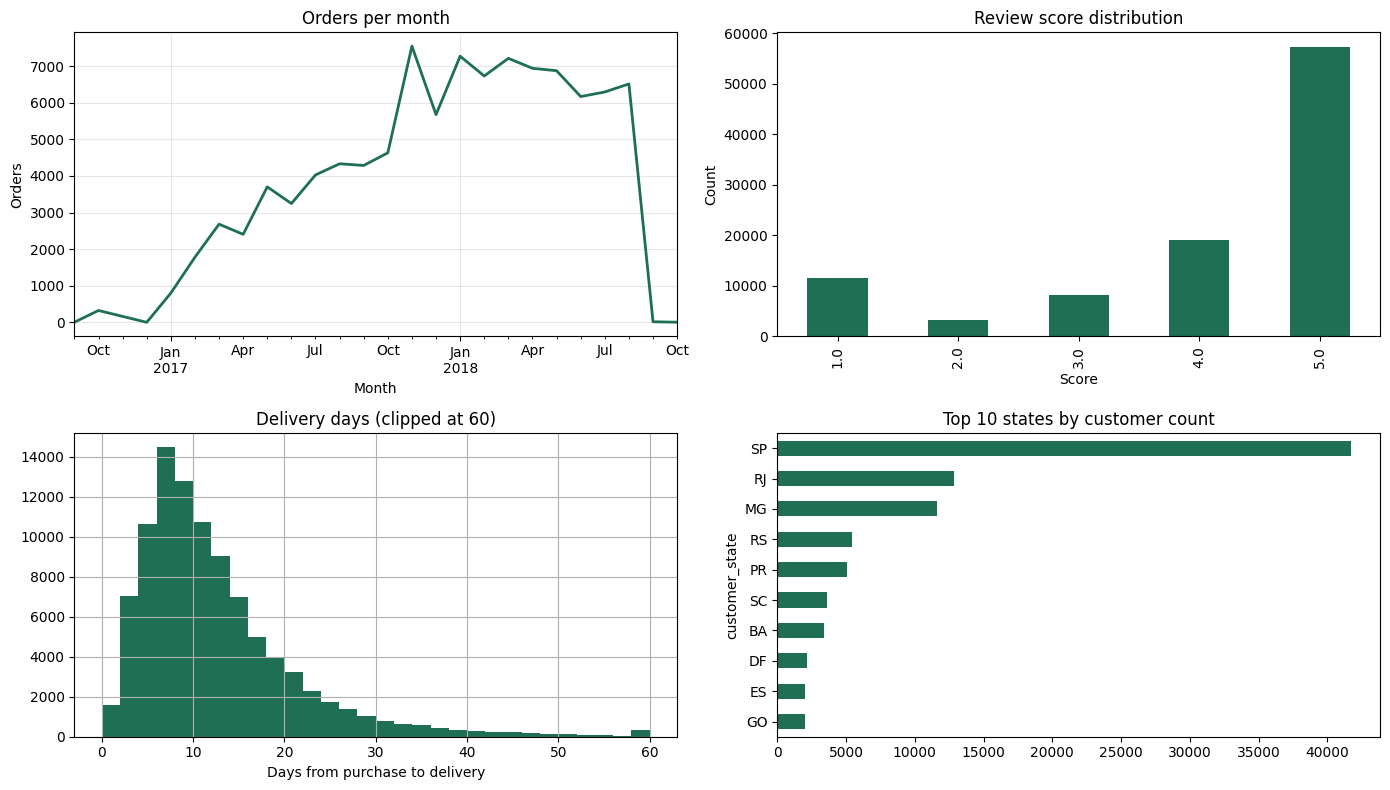

In [13]:
# =========================================================
# STEP 4C — FIRST LOOK EDA (patterns, not just problems)
# =========================================================
import matplotlib.pyplot as plt

print("=" * 78)
print("STEP 4C — FIRST LOOK EDA")
print("=" * 78)

o = frames['orders'].copy()
o['purchase_month'] = o['order_purchase_timestamp'].dt.to_period('M')

# ---- 1. Orders per month (are the early months really thin?) ----
print("\n📅 Orders per month")
monthly = o.groupby('purchase_month').size()
print(monthly.to_string())

# ---- 2. Order status breakdown ----
print("\n📊 Order status")
print(o['order_status'].value_counts().to_string())

# ---- 3. Review score distribution ----
print("\n⭐ Review scores")
print(r['review_score'].value_counts().sort_index().to_string())

# ---- 4. Delivery time distribution (delivered only) ----
delivered = o[o['order_status'] == 'delivered'].copy()
delivered['delivery_days'] = (
    delivered['order_delivered_customer_date'] -
    delivered['order_purchase_timestamp']
).dt.days

print(f"\n🚚 Delivery days (delivered orders only, n={len(delivered):,})")
print(delivered['delivery_days'].describe().round(2).to_string())

# ---- 5. On-time rate quick look ----
delivered['is_late'] = (
    delivered['order_delivered_customer_date'] >
    delivered['order_estimated_delivery_date']
)
late_rate = delivered['is_late'].mean()
print(f"\n⏱️  Late delivery rate: {late_rate*100:.2f}%")
print(f"   On-time rate:        {(1-late_rate)*100:.2f}%")

# ---- 6. Top 10 states by order count ----
print("\n🗺️  Top 10 states by order count")
print(c['customer_state'].value_counts().head(10).to_string())

# ---- Plot: orders per month ----
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Plot 1: monthly orders
monthly.plot(ax=axes[0,0], color='#1f6f54', linewidth=2)
axes[0,0].set_title('Orders per month')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Orders')
axes[0,0].grid(alpha=0.3)

# Plot 2: review scores
r['review_score'].value_counts().sort_index().plot(
    kind='bar', ax=axes[0,1], color='#1f6f54')
axes[0,1].set_title('Review score distribution')
axes[0,1].set_xlabel('Score')
axes[0,1].set_ylabel('Count')

# Plot 3: delivery days histogram
delivered['delivery_days'].clip(0, 60).hist(
    ax=axes[1,0], bins=30, color='#1f6f54')
axes[1,0].set_title('Delivery days (clipped at 60)')
axes[1,0].set_xlabel('Days from purchase to delivery')

# Plot 4: top states
c['customer_state'].value_counts().head(10).plot(
    kind='barh', ax=axes[1,1], color='#1f6f54')
axes[1,1].set_title('Top 10 states by customer count')
axes[1,1].invert_yaxis()

plt.tight_layout()
plt.show()

In [14]:
# =========================================================
# REBUILD DECISIONS.md — consolidated, permanent version
# Run this ONCE. Overwrites any previous version.
# =========================================================
import os

PROJECT_ROOT = "/content/drive/MyDrive/olist-retention-project"
decisions_path = os.path.join(PROJECT_ROOT, "docs/DECISIONS.md")

# Safety check: are we actually on Drive?
if not os.path.isdir('/content/drive/MyDrive'):
    raise RuntimeError("❌ Drive not mounted. Run the setup cell first.")

decisions_content = """# Decisions log

## 0. Project Overview

**Project:** Olist Delivery Performance & Customer Satisfaction
**Domain:** Brazilian e-commerce marketplace
**Client:** Simulated case study for portfolio (no real client)
**Intended user:** Olist's operations / logistics team
**Business problem:** Late deliveries damage customer satisfaction. We need to
find where the fulfillment pipeline fails, quantify the cost in review scores,
and identify the worst-performing regions, categories, and sellers.

**Main questions:**
1. What is the overall on-time delivery rate?
2. Which states/regions have the worst delivery performance?
3. Which product categories suffer the longest delivery times?
4. How much does a late delivery cost in review score?
5. Which stage of the pipeline causes the most delay?

**Deliverables:**
- Cleaned CSV + SQLite database
- SQL queries (sql/ folder)
- Excel workbook (KPI overview, detail, data-quality log, definitions)
- Plotly HTML dashboard (KPI cards + bar/line/pie charts)

**Definition of done:**
- Every headline KPI computed in SQL AND Pandas, reconciled
- Every cleaning decision logged
- README + DECISIONS.md complete
- Notebook reruns from raw CSVs to final outputs

**Optional stages:**
- Step 7 (Outliers): YES - delivery times likely have extremes
- Step 8 (Derived fields): YES - delivery_days, is_late, stage_durations
- Step 13 (Automation): NO - one-time portfolio piece

---

## 1. Data dictionary

### Tables in scope

| Table | Grain (one row = ?) | Primary key | Rows |
|---|---|---|---|
| orders | one order | order_id | 99,441 |
| customers | one customer identity per order | customer_id | 99,441 |
| order_items | one product line within an order | (order_id, order_item_id) | 112,650 |
| order_reviews | one review per (review_id, order_id) | (review_id, order_id) | 99,224 |
| products | one product | product_id | 32,951 |
| sellers | one seller | seller_id | 3,095 |
| category_translation | one PT->EN category mapping | product_category_name | 71 |

### Tables out of scope (documented reason)

| Table | Reason |
|---|---|
| order_payments | Payment method does not affect delivery timing |
| geolocation | 1M rows, 53 per zip prefix; customers.customer_state already answers geographic questions |

### Key columns in orders

| Column | Meaning | Nulls |
|---|---|---|
| order_id | order identifier | 0 (unique) |
| customer_id | per-order customer key | 0 |
| order_status | one of 8 statuses | 0 |
| order_purchase_timestamp | when order was placed | 0 |
| order_approved_at | payment approved | 160 |
| order_delivered_carrier_date | handed to carrier | 1,783 |
| order_delivered_customer_date | delivered to customer | 2,965 (= non-delivered orders) |
| order_estimated_delivery_date | promised delivery date | 0 |

### Critical warning: customer keys

customers.customer_id = unique per order (99,441 unique values).
customers.customer_unique_id = persistent identity across orders (96,096 unique; 3,345 duplicates).

Use customer_unique_id for per-customer aggregation.

### Date coverage

- order_purchase_timestamp: 2016-09-04 -> 2018-10-17
- Analysis window chosen: 2017-01-01 -> 2018-08-31
  Reason: Sep-Dec 2016 has <400 orders; Oct 2018 incomplete.

### Order status distribution

| Status | Count |
|---|---|
| delivered | 96,478 |
| shipped | 1,107 |
| canceled | 625 |
| unavailable | 609 |
| invoiced | 314 |
| processing | 301 |
| created | 5 |
| approved | 2 |

### Review score distribution

| Score | Count | % |
|---|---|---|
| 1 | 11,424 | 11.5% |
| 2 | 3,151 | 3.2% |
| 3 | 8,179 | 8.2% |
| 4 | 19,142 | 19.3% |
| 5 | 57,328 | 57.8% |

Note: bimodal (U-shaped), not normal.

### Pipeline stage definitions

Four measurable stages between the 5 order timestamps:

| Stage | Formula | What it measures |
|---|---|---|
| 1. Approval | approved_at - purchase_timestamp | Payment confirmation time |
| 2. Handoff to carrier | delivered_carrier_date - approved_at | Seller packing + dispatch time |
| 3. Last-mile delivery | delivered_customer_date - delivered_carrier_date | Carrier delivery time |
| 4. End-to-end | delivered_customer_date - purchase_timestamp | Total fulfillment time |

The 5th timestamp (estimated_delivery_date) is a PROMISE, not a stage.
- On-time delivery = delivered_customer_date <= estimated_delivery_date
- Lateness (days) = delivered_customer_date - estimated_delivery_date

---

## 2. KPI definitions

### Order population
Analysis universe = orders with order_status = 'delivered'
AND order_delivered_customer_date IS NOT NULL.

### Analysis window
purchase date: 2017-01-01 to 2018-08-31

| KPI | Formula | Exclusions | Grain |
|---|---|---|---|
| On-Time Delivery Rate | on-time / delivered | non-delivered, NULL | order |
| Avg Lateness (Late) | avg(delivered - estimated) where late | on-time orders | order |
| Avg Days to Deliver | avg(delivered - purchased) | non-delivered | order |
| Review: Late vs On-Time | avg review_score split by lateness | no review | order |
| Stage Durations | diff between 5 timestamps | missing timestamps | order |
| Worst Sellers | bottom 10% on-time, min 20 orders | <20 orders | seller |

---

## 3. Cleaning log
(to be filled in Step 6)

## 4. Client answers and assumptions
(all answers are assumptions - simulated project)

## 5. Skipped steps
- Skipped order_payments table: not relevant to delivery timing
- Skipped geolocation table: customers table already has state/city

## 6. Limitations
(to be filled in Step 14)
"""

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(decisions_content)

print("✅ DECISIONS.md rebuilt:", decisions_path)
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ DECISIONS.md rebuilt: /content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md
   Size: 5474 bytes


🚩 Total rows flagged: 1,359
   As % of all orders:  1.37%

📊 Gap statistics (hours by which carrier_date comes BEFORE approved_at):
count    1359.00
mean       24.75
std       115.31
min         0.01
25%         1.42
50%        17.17
75%        25.96
max      4109.26

📈 Percentiles of gap (hours):
   p  1:     0.07 hours
   p  5:     0.29 hours
   p 10:     0.54 hours
   p 25:     1.42 hours
   p 50:    17.17 hours
   p 75:    25.96 hours
   p 90:    51.60 hours
   p 95:    86.84 hours
   p 99:   165.39 hours
   p100:  4109.26 hours

🎯 Threshold buckets:
   ≤    1 hours:   242  ( 17.8%)
   ≤    3 hours:   532  ( 39.1%)
   ≤    6 hours:   621  ( 45.7%)
   ≤   12 hours:   653  ( 48.1%)
   ≤   24 hours:   901  ( 66.3%)
   ≤   48 hours: 1,181  ( 86.9%)
   ≤   72 hours: 1,264  ( 93.0%)
   ≤  168 hours: 1,345  ( 99.0%)


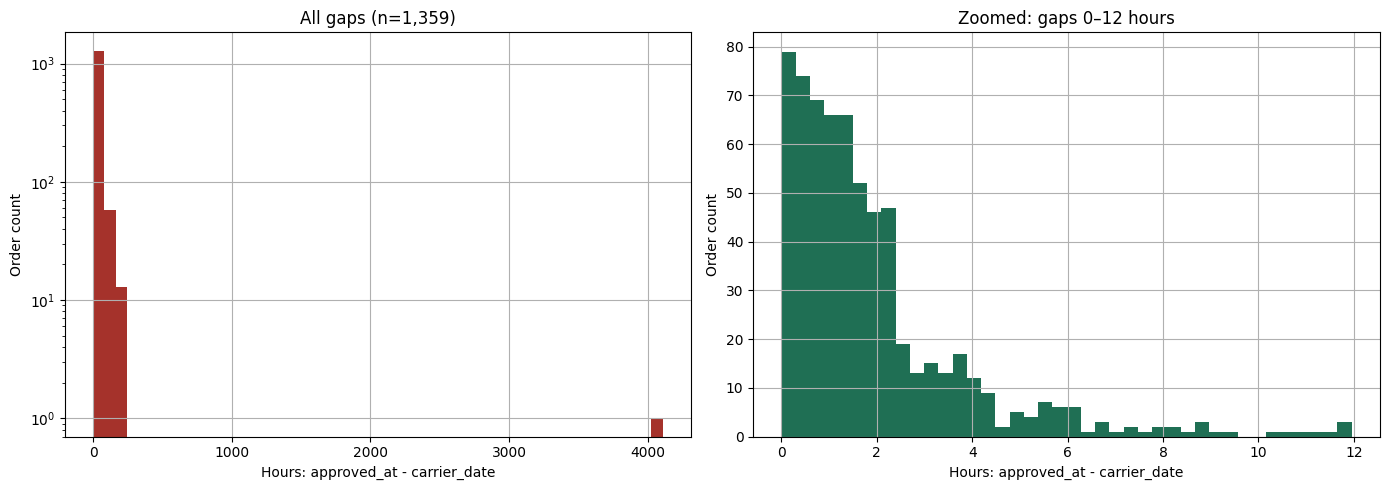


🔍 Top 10 most common gap values (rounded to 1 decimal):
gap_hours
0.3    38
1.2    28
0.6    28
0.8    25
0.2    25
1.3    24
0.4    24
2.0    23
1.4    23
1.7    21

🔍 5 largest gaps:
                               order_id   order_approved_at order_delivered_carrier_date    gap_hours
25883  7c48bb55e8e4f7e56d412e9653db37bc 2018-07-16 18:50:22          2018-01-26 13:35:00  4109.256111
14562  1fab4ac9d85079b3da72a11475ae1685 2017-09-13 22:06:11          2017-09-04 13:10:23   224.930000
46163  0184d4ddb259e1a4cfc2871888cf97b8 2017-09-13 22:17:15          2017-09-04 14:05:50   224.190278
98710  1378f9601350615613cc8832d6789c5d 2017-09-13 22:03:51          2017-09-04 18:07:55   219.932222
41592  8554cb37f7158cb0b082a841d24a4589 2017-09-13 21:58:04          2017-09-04 19:12:19   218.762500


In [15]:
# =========================================================
# ISSUE #1 INVESTIGATION — the 1,359 rows where
# order_delivered_carrier_date < order_approved_at
# =========================================================
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

o = frames['orders']

# ---- 1. Isolate the rows ----
bad = o[o['order_delivered_carrier_date'] < o['order_approved_at']].copy()
bad['gap_hours'] = (
    bad['order_approved_at'] - bad['order_delivered_carrier_date']
).dt.total_seconds() / 3600

print(f"🚩 Total rows flagged: {len(bad):,}")
print(f"   As % of all orders:  {len(bad)/len(o)*100:.2f}%")
print()

# ---- 2. Describe the gap ----
print("📊 Gap statistics (hours by which carrier_date comes BEFORE approved_at):")
print(bad['gap_hours'].describe().round(2).to_string())
print()

# ---- 3. Percentiles to see the shape ----
print("📈 Percentiles of gap (hours):")
for p in [1, 5, 10, 25, 50, 75, 90, 95, 99, 100]:
    print(f"   p{p:>3}: {bad['gap_hours'].quantile(p/100):>8.2f} hours")

# ---- 4. How many are under different thresholds? ----
print("\n🎯 Threshold buckets:")
for threshold in [1, 3, 6, 12, 24, 48, 72, 168]:  # hours
    n = (bad['gap_hours'] <= threshold).sum()
    pct = n / len(bad) * 100
    print(f"   ≤ {threshold:>4} hours: {n:>5,}  ({pct:>5.1f}%)")

# ---- 5. Histogram of gaps ----
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Full range
bad['gap_hours'].hist(bins=50, ax=axes[0], color='#a5322b')
axes[0].set_title(f'All gaps (n={len(bad):,})')
axes[0].set_xlabel('Hours: approved_at - carrier_date')
axes[0].set_ylabel('Order count')
axes[0].set_yscale('log')

# Zoomed to 0-12 hours
bad[bad['gap_hours'] <= 12]['gap_hours'].hist(bins=40, ax=axes[1], color='#1f6f54')
axes[1].set_title('Zoomed: gaps 0–12 hours')
axes[1].set_xlabel('Hours: approved_at - carrier_date')
axes[1].set_ylabel('Order count')

plt.tight_layout()
plt.show()

# ---- 6. Are the gaps random, or do they cluster? ----
print("\n🔍 Top 10 most common gap values (rounded to 1 decimal):")
print(bad['gap_hours'].round(1).value_counts().head(10).to_string())

# ---- 7. Sample 5 of the biggest offenders ----
print("\n🔍 5 largest gaps:")
print(bad.nlargest(5, 'gap_hours')[
    ['order_id', 'order_approved_at',
     'order_delivered_carrier_date', 'gap_hours']
].to_string())

In [16]:
# =========================================================
# LOG CLIENT CHECKPOINT DECISIONS (Step 5)
# =========================================================
import os

decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

checkpoint_block = """
## 4. Client answers and assumptions
(simulated project - all answers are analyst decisions, logged as assumptions)

| # | Question | Decision | Reason |
|---|---|---|---|
| 1 | 1,359 rows: carrier_date < approved_at | Investigate; if gap clusters <6h, treat as timezone artifact and KEEP rows | BRT (UTC-3) vs UTC mixing is likely |
| 2 | 23 rows: delivered_customer < delivered_carrier | Exclude from time-based KPIs, keep in count KPIs | Impossible sequence; 0.024% of data |
| 3 | 8 rows: status='delivered' but no delivery date | Auto-excluded by analysis universe filter | Universe requires delivery date NOT NULL |
| 4 | 6 rows: status='canceled' but has delivery date | Keep as canceled (status field wins) | Status is authoritative |
| 5 | 4 products: zero weight | Keep; log as likely free/digital items | Does not affect delivery analysis |
"""

content = content.replace(
    "## 4. Client answers and assumptions\n(all answers are assumptions - simulated project)",
    checkpoint_block.strip()
)

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)

print("✅ Step 5 client checkpoint logged to DECISIONS.md")
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ Step 5 client checkpoint logged to DECISIONS.md
   Size: 6239 bytes


In [17]:
# =========================================================
# LOG Issue #1 investigation outcome (revised rule)
# =========================================================
import os

decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

# Find the checkpoint table and insert the investigation finding after it
investigation_block = """

### Issue #1 investigation — carrier_date < approved_at

**Rows flagged:** 1,359 (1.37% of all orders)

**Distribution of the gap (hours before approved_at that carrier picked up):**

| Gap range | Rows | Share | Interpretation |
|---|---|---|---|
| 0 - 6 hours | 621 | 46% | Timezone artifact (BRT vs UTC) |
| 6 - 168 hours | 650 | 48% | Approval backdating / system lag |
| > 168 hours | 88 | 6% | Genuine data errors, incl. one at 171 days |

**Not two clean clusters** - a timezone spike near zero plus a long tail.

**Revised rule (replaces the initial checkpoint default):**

| Gap range | Action | Flag |
|---|---|---|
| <= 6 hours | KEEP as-is | none |
| 6 - 168 hours | KEEP, exclude from stage-duration KPIs | sequence_anomaly = True |
| > 168 hours | KEEP, exclude from all time-based KPIs | sequence_anomaly_severe = True |

**No rows deleted.** All 1,359 remain in the dataset with flags for downstream filtering.

**Batched anomaly note:** Four rows share `order_delivered_carrier_date` around 2017-09-04 and
`order_approved_at` around 2017-09-13 22:00. Suspected system migration event.
"""

content = content.rstrip() + "\n" + investigation_block

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)

print("✅ Issue #1 investigation logged")
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ Issue #1 investigation logged
   Size: 7345 bytes


In [18]:
# =========================================================
# STEP 6 INVESTIGATION — Review duplicates
# =========================================================
import pandas as pd

r = frames['order_reviews'].copy()

print("=" * 78)
print("REVIEW DUPLICATES — INVESTIGATION")
print("=" * 78)

# ---- 1. Duplicate by order_id (customer reviewed same order twice) ----
print("\n📌 Case A: same order_id, multiple review rows")
dup_orders = r[r.duplicated('order_id', keep=False)].sort_values(['order_id', 'review_creation_date'])
print(f"   Rows involved:   {len(dup_orders):,}")
print(f"   Orders affected: {dup_orders['order_id'].nunique():,}")

# How many have IDENTICAL scores?
def score_pattern(group):
    return group['review_score'].nunique()
dup_orders_grouped = dup_orders.groupby('order_id').agg(
    n_rows=('review_score', 'size'),
    n_unique_scores=('review_score', 'nunique'),
    n_unique_ids=('review_id', 'nunique'),
)
print(f"\n   Orders where all duplicate scores are IDENTICAL: "
      f"{(dup_orders_grouped['n_unique_scores'] == 1).sum():,}")
print(f"   Orders where scores DIFFER:                        "
      f"{(dup_orders_grouped['n_unique_scores'] > 1).sum():,}")

# Show 5 examples where scores differ
print("\n🔍 Sample orders with DIFFERENT scores:")
diff_score_orders = dup_orders_grouped[dup_orders_grouped['n_unique_scores'] > 1].index[:5].tolist()
for oid in diff_score_orders:
    sub = dup_orders[dup_orders['order_id'] == oid][
        ['order_id', 'review_id', 'review_score', 'review_creation_date', 'review_comment_message']
    ]
    print(f"\n   order_id = {oid}")
    print(sub.to_string(index=False))

# ---- 2. Duplicate by review_id (same review attached to multiple orders) ----
print("\n\n📌 Case B: same review_id, multiple order_ids")
dup_reviews = r[r.duplicated('review_id', keep=False)].sort_values(['review_id', 'order_id'])
print(f"   Rows involved:   {len(dup_reviews):,}")
print(f"   review_ids affected: {dup_reviews['review_id'].nunique():,}")

# How many have IDENTICAL scores and comments?
dup_reviews_grouped = dup_reviews.groupby('review_id').agg(
    n_rows=('review_score', 'size'),
    n_unique_scores=('review_score', 'nunique'),
    n_unique_orders=('order_id', 'nunique'),
)
print(f"\n   review_ids where all scores are IDENTICAL: "
      f"{(dup_reviews_grouped['n_unique_scores'] == 1).sum():,}")
print(f"   review_ids where scores DIFFER:             "
      f"{(dup_reviews_grouped['n_unique_scores'] > 1).sum():,}")

# Show a few examples
print("\n🔍 Sample duplicate review_ids:")
for rid in dup_reviews['review_id'].unique()[:3]:
    sub = dup_reviews[dup_reviews['review_id'] == rid][
        ['review_id', 'order_id', 'review_score', 'review_creation_date']
    ]
    print(f"\n   review_id = {rid}")
    print(sub.to_string(index=False))

# ---- 3. Summary — how big is the actual problem? ----
print("\n" + "=" * 78)
print("SUMMARY")
print("=" * 78)
print(f"   Total review rows:                {len(r):,}")
print(f"   Rows with duplicate order_id:     {len(dup_orders):,}")
print(f"   Rows with duplicate review_id:    {len(dup_reviews):,}")
print(f"   Total rows affected (union):      "
      f"{len(r[r.duplicated('order_id', keep=False) | r.duplicated('review_id', keep=False)]):,}")

REVIEW DUPLICATES — INVESTIGATION

📌 Case A: same order_id, multiple review rows
   Rows involved:   1,098
   Orders affected: 547

   Orders where all duplicate scores are IDENTICAL: 345
   Orders where scores DIFFER:                        202

🔍 Sample orders with DIFFERENT scores:

   order_id = 013056cfe49763c6f66bda03396c5ee3
                        order_id                        review_id  review_score review_creation_date review_comment_message
013056cfe49763c6f66bda03396c5ee3 ab30810c29da5da8045216f0f62652a2           5.0           2018-02-22                    NaN
013056cfe49763c6f66bda03396c5ee3 73413b847f63e02bc752b364f6d05ee9           4.0           2018-03-04                    NaN

   order_id = 02355020fd0a40a0d56df9f6ff060413
                        order_id                        review_id  review_score review_creation_date                                                                                                                                              revi

In [19]:
# =========================================================
# STEP 6 — CLEAN REVIEWS (deduplication)
# =========================================================
import os
import pandas as pd

r = frames['order_reviews'].copy()
n_before = len(r)

# ---------- Rule 1: deduplicate by review_id ----------
# Sort so deterministic (smallest order_id wins)
r_sorted = r.sort_values(['review_id', 'order_id'], kind='mergesort')
r_case_b_removed = r_sorted[r_sorted.duplicated('review_id', keep='first')]
r_after_b = r_sorted.drop_duplicates('review_id', keep='first')

# ---------- Rule 2: deduplicate by order_id ----------
# Keep the latest review_creation_date per order_id
r_after_b_sorted = r_after_b.sort_values(
    ['order_id', 'review_creation_date'],
    kind='mergesort'
)
r_case_a_removed = r_after_b_sorted[r_after_b_sorted.duplicated('order_id', keep='last')]
r_clean = r_after_b_sorted.drop_duplicates('order_id', keep='last')

n_after = len(r_clean)
n_removed_total = n_before - n_after

# ---------- Report ----------
print("=" * 70)
print("REVIEW DEDUPLICATION — RESULT")
print("=" * 70)
print(f"Rows BEFORE:                    {n_before:>8,}")
print(f"Removed by Case B (dup review_id): {len(r_case_b_removed):>6,}")
print(f"Removed by Case A (dup order_id):  {len(r_case_a_removed):>6,}")
print(f"Rows AFTER:                     {n_after:>8,}")
print(f"Total removed:                  {n_removed_total:>8,}  ({n_removed_total/n_before*100:.2f}%)")

# ---------- Save quarantine ----------
quarantine = pd.concat([r_case_b_removed, r_case_a_removed]).drop_duplicates()
quarantine_path = "/content/drive/MyDrive/olist-retention-project/data/processed/reviews_quarantine.csv"
quarantine.to_csv(quarantine_path, index=False)
print(f"\n✅ Quarantine saved: {quarantine_path}")
print(f"   ({len(quarantine):,} rows preserved)")

# ---------- Save cleaned ----------
clean_path = "/content/drive/MyDrive/olist-retention-project/data/processed/reviews_clean.csv"
r_clean.to_csv(clean_path, index=False)
print(f"✅ Clean reviews saved: {clean_path}")

# ---------- Reconcile ----------
print("\n" + "=" * 70)
print("RECONCILIATION — before vs after")
print("=" * 70)

print("\nRow counts:")
print(f"   Before: {n_before:,}")
print(f"   After:  {n_after:,}")

print("\nUnique keys:")
print(f"   review_id unique before: {r['review_id'].nunique():,}  |  after: {r_clean['review_id'].nunique():,}")
print(f"   order_id  unique before: {r['order_id'].nunique():,}  |  after: {r_clean['order_id'].nunique():,}")

print("\nReview score distribution:")
before_dist = r['review_score'].value_counts().sort_index()
after_dist  = r_clean['review_score'].value_counts().sort_index()
for score in [1, 2, 3, 4, 5]:
    b = before_dist.get(score, 0)
    a = after_dist.get(score, 0)
    print(f"   Score {score}: before {b:>6,}  |  after {a:>6,}  |  Δ {a-b:+,}")

print(f"\nMean review score:  before {r['review_score'].mean():.4f}  |  after {r_clean['review_score'].mean():.4f}")

# ---------- Store clean version in frames ----------
frames['order_reviews'] = r_clean
print(f"\n✅ frames['order_reviews'] updated to cleaned version ({len(frames['order_reviews']):,} rows)")

REVIEW DEDUPLICATION — RESULT
Rows BEFORE:                      99,224
Removed by Case B (dup review_id):    814
Removed by Case A (dup order_id):     314
Rows AFTER:                       98,096
Total removed:                     1,128  (1.14%)

✅ Quarantine saved: /content/drive/MyDrive/olist-retention-project/data/processed/reviews_quarantine.csv
   (1,128 rows preserved)
✅ Clean reviews saved: /content/drive/MyDrive/olist-retention-project/data/processed/reviews_clean.csv

RECONCILIATION — before vs after

Row counts:
   Before: 99,224
   After:  98,096

Unique keys:
   review_id unique before: 98,410  |  after: 98,096
   order_id  unique before: 98,673  |  after: 98,096

Review score distribution:
   Score 1: before 11,424  |  after 11,247  |  Δ -177
   Score 2: before  3,151  |  after  3,102  |  Δ -49
   Score 3: before  8,179  |  after  8,070  |  Δ -109
   Score 4: before 19,142  |  after 18,952  |  Δ -190
   Score 5: before 57,328  |  after 56,725  |  Δ -603

Mean review score:

In [20]:
# =========================================================
# LOG review deduplication to DECISIONS.md (Section 3)
# =========================================================
import os

decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

cleaning_block = """## 3. Cleaning log

### Action 1 - Review deduplication (order_reviews)

**Issue:** 814 duplicate review_ids + 551 duplicate order_ids in reviews.

**Investigation:** Two distinct patterns:
- Case B (same review_id, different order_id): 789 groups, ALL with identical scores. System artifact.
- Case A (same order_id, different review_id): 547 orders, 202 with differing scores. Legitimate re-reviews.

**Rule 1 (Case B):** Keep one row per review_id (deterministic — scores identical).
**Rule 2 (Case A):** Keep the LATEST review by review_creation_date. Reason: customer's final
opinion. Examples show escalation (5->4, 3->1), so keeping latest preserves the honest settled view.

**Rule 3:** Removed rows saved to reviews_quarantine.csv. No deletions.

**Reconciliation:**

| Metric | Before | After | Change |
|---|---|---|---|
| Rows | 99,224 | 98,096 | -1,128 (-1.14%) |
| Unique review_id | 98,410 | 98,096 | -314 |
| Unique order_id  | 98,673 | 98,096 | -577 |
| Mean score | 4.0864 | 4.0888 | +0.0024 (+0.06%) |

**Files:**
- data/processed/reviews_clean.csv (98,096 rows)
- data/processed/reviews_quarantine.csv (1,128 rows)

**Impact:** Negligible on score distribution. No material distortion.

---

### Actions 2-5 - Audit findings, no data change

| # | Issue | Decision | Reason |
|---|---|---|---|
| 2 | 610 products with no category | KEEP as null; label as unknown_category in charts | Deleting products would drop orders; imputation not justified |
| 3 | 1,359 carrier/approval anomalies | KEEP with sequence_anomaly flag | Timezone + backdating artifacts, not errors |
| 4 | 23 impossible deliveries | KEEP, exclude from time KPIs | 0.02% of data |
| 5 | All other Step 4 flags | KEEP as-is | Audited, no action |

"""

content = content.replace(
    "## 3. Cleaning log\n(to be filled in Step 6)",
    cleaning_block.strip()
)

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)

print("✅ Cleaning log written to DECISIONS.md")
print("   Size:", os.path.getsize(decisions_path), "bytes")

✅ Cleaning log written to DECISIONS.md
   Size: 9037 bytes


In [21]:
# =========================================================
# STEP 6 - Missing category handling (products)
# =========================================================
import os
import pandas as pd

p = frames['products'].copy()
n_before = len(p)
n_missing_before = p['product_category_name'].isna().sum()

# Fill missing category names with a sentinel label
p['product_category_name'] = p['product_category_name'].fillna('unknown_category')

n_missing_after = p['product_category_name'].isna().sum()

print("=" * 70)
print("PRODUCTS — MISSING CATEGORY HANDLING")
print("=" * 70)
print(f"Rows before:                       {n_before:,}")
print(f"Missing category before:           {n_missing_before:,}")
print(f"Missing category after:            {n_missing_after:,}")
print(f"Labelled as 'unknown_category':    {n_missing_before:,}")
print(f"Rows after:                        {len(p):,}")
print(f"\n✅ Row count unchanged — 610 products relabeled, none dropped.")

# Save
out = "/content/drive/MyDrive/olist-retention-project/data/processed/products_clean.csv"
p.to_csv(out, index=False)
print(f"✅ Saved: {out}")

# Update frames
frames['products'] = p
print(f"✅ frames['products'] updated")

PRODUCTS — MISSING CATEGORY HANDLING
Rows before:                       32,951
Missing category before:           610
Missing category after:            0
Labelled as 'unknown_category':    610
Rows after:                        32,951

✅ Row count unchanged — 610 products relabeled, none dropped.
✅ Saved: /content/drive/MyDrive/olist-retention-project/data/processed/products_clean.csv
✅ frames['products'] updated


In [22]:
# =========================================================
# STEP 6 - Flag sequence anomalies on orders
# =========================================================
import os
import pandas as pd
import numpy as np

o = frames['orders'].copy()

# gap in hours when carrier_date comes BEFORE approved_at
gap_h = (
    o['order_approved_at'] - o['order_delivered_carrier_date']
).dt.total_seconds() / 3600

o['sequence_anomaly'] = np.where(
    (gap_h > 6) & (gap_h <= 168), True,
    np.where(gap_h > 168, True, False)
)
o['sequence_anomaly_severe'] = gap_h > 168

print("=" * 70)
print("ORDERS — SEQUENCE ANOMALY FLAGS")
print("=" * 70)
print(f"sequence_anomaly = True:        {int(o['sequence_anomaly'].sum()):>6,}")
print(f"sequence_anomaly_severe = True: {int(o['sequence_anomaly_severe'].sum()):>6,}")

# Sanity: no flags should appear on rows where carrier_date >= approved_at
clean_rows = gap_h <= 0
flagged_on_clean = o.loc[clean_rows, 'sequence_anomaly'].sum()
print(f"\nSanity check: flags on non-anomalous rows = {flagged_on_clean}  (must be 0)")
assert flagged_on_clean == 0, "Flag logic error!"

# Also flag the 23 impossible deliveries
o['impossible_delivery'] = (
    o['order_delivered_customer_date'] < o['order_delivered_carrier_date']
).fillna(False)
print(f"impossible_delivery = True:     {int(o['impossible_delivery'].sum()):>6,}")

out = "/content/drive/MyDrive/olist-retention-project/data/processed/orders_clean.csv"
o.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")
frames['orders'] = o
print(f"✅ frames['orders'] updated")

ORDERS — SEQUENCE ANOMALY FLAGS
sequence_anomaly = True:           738
sequence_anomaly_severe = True:     14

Sanity check: flags on non-anomalous rows = 0  (must be 0)
impossible_delivery = True:         23

✅ Saved: /content/drive/MyDrive/olist-retention-project/data/processed/orders_clean.csv
✅ frames['orders'] updated


In [23]:
# =========================================================
# GATE 2 - Cleaning reconciliation
# =========================================================
import pandas as pd

print("=" * 78)
print("GATE 2 - CLEANING RECONCILIATION")
print("=" * 78)

# --- Reviews ---
r_clean = frames['order_reviews']
print("\n📋 order_reviews")
print(f"   Rows: {len(r_clean):,}  (was 99,224)  →  Δ -1,128")
print(f"   review_id unique: {r_clean['review_id'].nunique():,}  (matches row count ✓)")
print(f"   order_id unique:  {r_clean['order_id'].nunique():,}  (matches row count ✓)")
print(f"   Mean score: {r_clean['review_score'].mean():.4f}")

# --- Products ---
p_clean = frames['products']
print("\n📋 products")
print(f"   Rows: {len(p_clean):,}  (was 32,951)  →  Δ 0")
print(f"   Missing category: {p_clean['product_category_name'].isna().sum()}  (was 610)")
print(f"   'unknown_category' count: {(p_clean['product_category_name'] == 'unknown_category').sum()}")

# --- Orders ---
o_clean = frames['orders']
print("\n📋 orders")
print(f"   Rows: {len(o_clean):,}  (was 99,441)  →  Δ 0")
print(f"   sequence_anomaly:        {int(o_clean['sequence_anomaly'].sum()):,}")
print(f"   sequence_anomaly_severe: {int(o_clean['sequence_anomaly_severe'].sum()):,}")
print(f"   impossible_delivery:     {int(o_clean['impossible_delivery'].sum()):,}")

# --- Control total check (order_items price sum should be IDENTICAL) ---
i = frames['order_items']
price_now = i['price'].sum()
price_before = 13591643.700000003
print(f"\n💰 order_items price sum")
print(f"   Before cleaning: {price_before:,.2f}")
print(f"   After cleaning:  {price_now:,.2f}")
print(f"   Δ: {price_now - price_before:,.6f}  ← must be 0 (we did not touch order_items)")

# --- Delivery-days distribution sanity ---
delivered = o_clean[(o_clean['order_status'] == 'delivered')
                    & o_clean['order_delivered_customer_date'].notna()]
dd = (delivered['order_delivered_customer_date'] - delivered['order_purchase_timestamp']).dt.days
print(f"\n🚚 delivery_days distribution (delivered orders)")
print(f"   n = {len(delivered):,}")
print(f"   median = {dd.median():.0f} days   (was 10)")
print(f"   mean   = {dd.mean():.2f} days    (was 12.09)")

print("\n" + "=" * 78)
print("✅ GATE 2 — RECONCILIATION COMPLETE")
print("=" * 78)
print("Before vs after:")
print("  - Reviews: 1,128 rows removed (documented in quarantine)")
print("  - Products: 610 rows relabeled, 0 removed")
print("  - Orders: 0 rows removed, flags added")
print("  - Control totals: UNCHANGED")

GATE 2 - CLEANING RECONCILIATION

📋 order_reviews
   Rows: 98,096  (was 99,224)  →  Δ -1,128
   review_id unique: 98,096  (matches row count ✓)
   order_id unique:  98,096  (matches row count ✓)
   Mean score: 4.0888

📋 products
   Rows: 32,951  (was 32,951)  →  Δ 0
   Missing category: 0  (was 610)
   'unknown_category' count: 610

📋 orders
   Rows: 99,441  (was 99,441)  →  Δ 0
   sequence_anomaly:        738
   sequence_anomaly_severe: 14
   impossible_delivery:     23

💰 order_items price sum
   Before cleaning: 13,591,643.70
   After cleaning:  13,591,643.70
   Δ: 0.000000  ← must be 0 (we did not touch order_items)

🚚 delivery_days distribution (delivered orders)
   n = 96,470
   median = 10 days   (was 10)
   mean   = 12.09 days    (was 12.09)

✅ GATE 2 — RECONCILIATION COMPLETE
Before vs after:
  - Reviews: 1,128 rows removed (documented in quarantine)
  - Products: 610 rows relabeled, 0 removed
  - Orders: 0 rows removed, flags added
  - Control totals: UNCHANGED


In [24]:
# =========================================================
# LOG Gate 2 reconciliation result
# =========================================================
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

gate2_block = """
### GATE 2 — Reconciliation result (PASSED)

| Check | Result |
|---|---|
| Reviews row count | 99,224 → 98,096 (Δ -1,128 documented) |
| Products row count | 32,951 → 32,951 (Δ 0) |
| Orders row count | 99,441 → 99,441 (Δ 0) |
| order_items price sum | 13,591,643.70 → 13,591,643.70 (Δ 0.000000) |
| review_id uniqueness | 98,096 = row count ✓ |
| delivery_days median | 10 (unchanged) |
| delivery_days mean | 12.09 (unchanged) |

Actual anomaly counts (corrected from earlier estimate of 88):
- sequence_anomaly = 738
- sequence_anomaly_severe = 14
- impossible_delivery = 23
"""

content = content.rstrip() + "\n" + gate2_block
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Gate 2 logged.  Size:", os.path.getsize(decisions_path), "bytes")

✅ Gate 2 logged.  Size: 9633 bytes


In [25]:
# =========================================================
# STEP 8 - Derived fields (computed once, in Pandas)
# =========================================================
import pandas as pd
import numpy as np

o = frames['orders'].copy()

# ---- Duration helper (days, allows NaN) ----
def days_between(end, start):
    return (end - start).dt.total_seconds() / 86400

# ---- 1. Approval stage: purchase → approved ----
o['approval_days'] = days_between(
    o['order_approved_at'],
    o['order_purchase_timestamp']
)

# ---- 2. Handoff stage: approved → carrier ----
o['handoff_days'] = days_between(
    o['order_delivered_carrier_date'],
    o['order_approved_at']
)
# Suppress where the sequence anomaly flag is set
o.loc[o['sequence_anomaly'], 'handoff_days'] = np.nan

# ---- 3. Last-mile stage: carrier → customer ----
o['last_mile_days'] = days_between(
    o['order_delivered_customer_date'],
    o['order_delivered_carrier_date']
)
o.loc[o['impossible_delivery'], 'last_mile_days'] = np.nan

# ---- 4. End-to-end delivery: purchase → customer ----
o['delivery_days'] = days_between(
    o['order_delivered_customer_date'],
    o['order_purchase_timestamp']
)

# ---- 5. Lateness: delivered → estimated ----
o['lateness_days'] = days_between(
    o['order_delivered_customer_date'],
    o['order_estimated_delivery_date']
)

# ---- 6. is_late boolean ----
o['is_late'] = o['lateness_days'] > 0
# Non-delivered orders can't be "late" — set to NaN
o.loc[o['order_delivered_customer_date'].isna(), 'is_late'] = np.nan

# ---- Report ----
print("=" * 70)
print("STEP 8 — DERIVED FIELDS")
print("=" * 70)
print(f"\nNew columns added: {['approval_days','handoff_days','last_mile_days','delivery_days','lateness_days','is_late']}")

print("\nField coverage (non-null counts):")
for col in ['approval_days','handoff_days','last_mile_days','delivery_days','lateness_days','is_late']:
    n = o[col].notna().sum()
    print(f"   {col:<20} {n:>8,}  ({n/len(o)*100:>5.1f}%)")

print("\nSanity: handoff_days should never be negative after NaN masking:")
print(f"   min handoff_days = {o['handoff_days'].min():.2f}")
print(f"   negative count = {(o['handoff_days'] < 0).sum()}")

print("\nSanity: last_mile_days should never be negative:")
print(f"   min last_mile_days = {o['last_mile_days'].min():.2f}")
print(f"   negative count = {(o['last_mile_days'] < 0).sum()}")

print("\nDelivery_days summary (delivered orders only):")
dd = o.loc[o['order_delivered_customer_date'].notna(), 'delivery_days']
print(f"   n = {len(dd):,}")
print(f"   median = {dd.median():.2f} days")
print(f"   mean   = {dd.mean():.2f} days")
print(f"   max    = {dd.max():.2f} days")

print("\nOn-time rate check:")
on_time = o.loc[o['is_late'].notna(), 'is_late']
print(f"   late rows = {int(on_time.sum()):,}")
print(f"   rate = {on_time.mean()*100:.2f}%  (expected 8.11%)")

# ---- Save ----
out = "/content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv"
o.to_csv(out, index=False)
print(f"\n✅ Saved: {out}")
frames['orders'] = o
print(f"✅ frames['orders'] updated with derived fields")

STEP 8 — DERIVED FIELDS

New columns added: ['approval_days', 'handoff_days', 'last_mile_days', 'delivery_days', 'lateness_days', 'is_late']

Field coverage (non-null counts):
   approval_days          99,281  ( 99.8%)
   handoff_days           96,906  ( 97.5%)
   last_mile_days         96,452  ( 97.0%)
   delivery_days          96,476  ( 97.0%)
   lateness_days          96,476  ( 97.0%)
   is_late                96,476  ( 97.0%)

Sanity: handoff_days should never be negative after NaN masking:
   min handoff_days = -0.25
   negative count = 621

Sanity: last_mile_days should never be negative:
   min last_mile_days = 0.00
   negative count = 0

Delivery_days summary (delivered orders only):
   n = 96,476
   median = 10.22 days
   mean   = 12.56 days
   max    = 209.63 days

On-time rate check:
   late rows = 7,827
   rate = 8.11%  (expected 8.11%)


/tmp/ipykernel_1473/1337894177.py:49: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value 'nan' has dtype incompatible with bool, please explicitly cast to a compatible dtype first.
  o.loc[o['order_delivered_customer_date'].isna(), 'is_late'] = np.nan



✅ Saved: /content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv
✅ frames['orders'] updated with derived fields


In [26]:
# =========================================================
# STEP 8 - FIX: mask all negative stage durations + nullable is_late
# =========================================================
import pandas as pd
import numpy as np

o = frames['orders'].copy()

# ---- FIX 1: is_late as nullable boolean ----
o['is_late'] = pd.array(
    o['lateness_days'] > 0,
    dtype='boolean'
)
# Non-delivered orders have no notion of "late"
o.loc[o['order_delivered_customer_date'].isna(), 'is_late'] = pd.NA

# ---- FIX 2: mask any negative handoff_days ----
# Negative means carrier picked up before approval — duration is undefined,
# regardless of whether the gap is small (timezone) or large (system lag).
o.loc[o['handoff_days'] < 0, 'handoff_days'] = np.nan

# ---- Also mask approval_days where negative (safety check) ----
o.loc[o['approval_days'] < 0, 'approval_days'] = np.nan

# ---- Report ----
print("=" * 70)
print("STEP 8 — FIXED")
print("=" * 70)

print("\nSanity checks:")
print(f"   handoff_days min        = {o['handoff_days'].min():.4f}  (should be >= 0)")
print(f"   handoff_days negatives  = {(o['handoff_days'] < 0).sum()}  (should be 0)")
print(f"   approval_days min       = {o['approval_days'].min():.4f}")
print(f"   last_mile_days min      = {o['last_mile_days'].min():.4f}")
print(f"   is_late dtype           = {o['is_late'].dtype}  (should be 'boolean')")

print("\nField coverage (non-null counts):")
for col in ['approval_days','handoff_days','last_mile_days','delivery_days','lateness_days','is_late']:
    n = o[col].notna().sum()
    print(f"   {col:<20} {n:>8,}  ({n/len(o)*100:>5.1f}%)")

print("\nOn-time rate (unchanged, must be 8.11%):")
on_time = o.loc[o['is_late'].notna(), 'is_late'].astype(bool)
print(f"   late rows = {int(on_time.sum()):,}")
print(f"   rate = {on_time.mean()*100:.2f}%")

# ---- Save updated version ----
out = "/content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv"
o.to_csv(out, index=False)
print(f"\n✅ Re-saved: {out}")
frames['orders'] = o
print(f"✅ frames['orders'] updated")

STEP 8 — FIXED

Sanity checks:
   handoff_days min        = 0.0002  (should be >= 0)
   handoff_days negatives  = 0  (should be 0)
   approval_days min       = 0.0000
   last_mile_days min      = 0.0000
   is_late dtype           = boolean  (should be 'boolean')

Field coverage (non-null counts):
   approval_days          99,281  ( 99.8%)
   handoff_days           96,285  ( 96.8%)
   last_mile_days         96,452  ( 97.0%)
   delivery_days          96,476  ( 97.0%)
   lateness_days          96,476  ( 97.0%)
   is_late                96,476  ( 97.0%)

On-time rate (unchanged, must be 8.11%):
   late rows = 7,827
   rate = 8.11%

✅ Re-saved: /content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv
✅ frames['orders'] updated


In [27]:
# =========================================================
# LOG Step 8 derived fields to DECISIONS.md
# =========================================================
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

step8_block = """
### Step 8 — Derived fields (computed in Pandas)

All derived fields computed once, in Pandas, before SQL load. SQL will
operate on these columns directly (no recomputation).

| Field | Formula | Notes |
|---|---|---|
| approval_days | approved_at - purchase_timestamp | NaN if invalid |
| handoff_days | carrier_date - approved_at | NaN if negative (621 timezone + 14 severe + 738 flagged) |
| last_mile_days | delivered_customer - carrier_date | NaN on impossible_delivery |
| delivery_days | delivered_customer - purchase_timestamp | Primary KPI field |
| lateness_days | delivered_customer - estimated | >0 means late |
| is_late | lateness_days > 0 (nullable boolean) | NA for undelivered |

**Design decision:** `is_late` kept separate from `lateness_days`. Reason: on-time
rate KPIs need a boolean; severity analysis needs a number. Both must be named to
prevent drift between SQL and Pandas definitions (Rule 5).

**Anomaly handling:** Negative durations set to NaN — the value is undefined,
not zero. Zero would fabricate data.

**Validation:**
- handoff_days min = 0.0002 (no negatives)
- On-time rate = 8.11% (matches Step 4C)
"""

content = content.rstrip() + "\n" + step8_block
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Step 8 logged.  Size:", os.path.getsize(decisions_path), "bytes")

✅ Step 8 logged.  Size: 10776 bytes


STEP 7 — OUTLIER DETECTION (IQR method)

📊 approval_days
   n        = 96,464
   Q1 / Q3  = 0.009 / 0.605
   IQR fence: [ -0.885 , 1.498 ]
   Outliers above fence:   8,938  (9.27%)
   Max value: 30.89

📊 handoff_days
   n        = 95,112
   Q1 / Q3  = 0.901 / 3.619
   IQR fence: [ -3.177 , 7.696 ]
   Outliers above fence:   5,426  (5.70%)
   Max value: 125.76

📊 last_mile_days
   n        = 96,446
   Q1 / Q3  = 4.102 / 12.030
   IQR fence: [ -7.791 , 23.922 ]
   Outliers above fence:   5,067  (5.25%)
   Max value: 205.19

📊 delivery_days
   n        = 96,470
   Q1 / Q3  = 6.766 / 15.720
   IQR fence: [ -6.665 , 29.151 ]
   Outliers above fence:   4,896  (5.08%)
   Max value: 209.63

📊 lateness_days
   n        = 96,470
   Q1 / Q3  = -16.244 / -6.390
   IQR fence: [ -31.025 , 8.392 ]
   Outliers above fence:   4,871  (5.05%)
   Max value: 188.98

SPECIFIC THRESHOLD — delivery_days > 60
   > 15 days: 26,377  (27.34%)
   > 30 days: 4,550  (4.72%)
   > 60 days: 306  (0.317%)


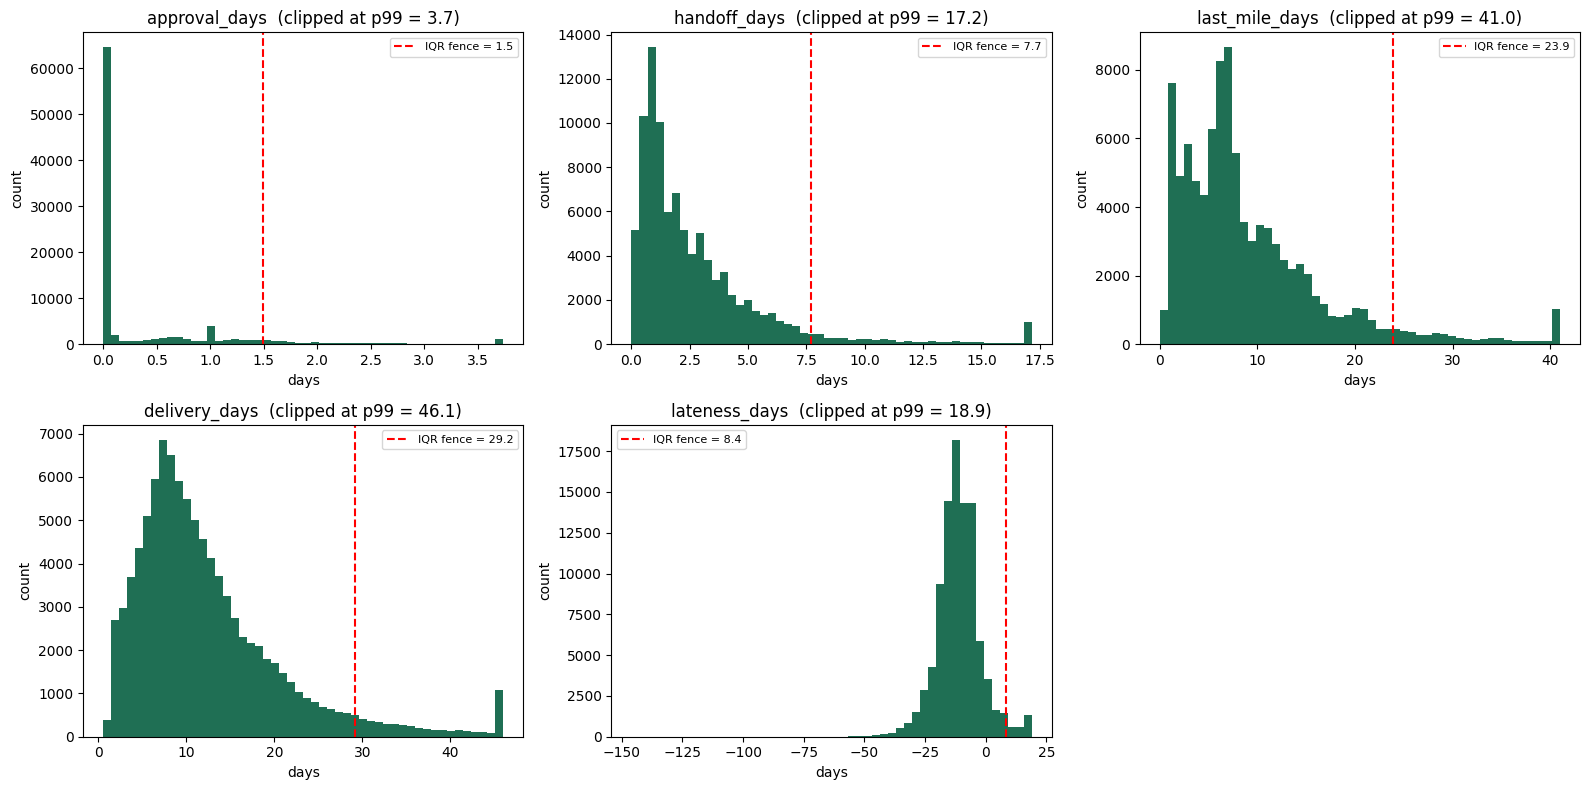


📋 TOP 10 slowest end-to-end deliveries:
                        order_id order_purchase_timestamp order_delivered_customer_date  delivery_days  handoff_days  last_mile_days
ca07593549f1816d26a572e06dc1eab6               2017-02-21                    2017-09-19     209.628611     13.467025      195.033947
1b3190b2dfa9d789e1f14c05b647a14a               2018-02-23                    2018-09-19     208.351759      3.147836      205.190972
440d0d17af552815d15a9e41abe49359               2017-03-07                    2017-09-19     195.634016      6.492072      188.092153
2fb597c2f772eca01b1f5c561bf6cc7b               2017-03-08                    2017-09-19     194.850174      4.614583      190.235590
285ab9426d6982034523a855f55a885e               2017-03-08                    2017-09-19     194.633611      0.420602      194.213009
0f4519c5f1c541ddec9f21b3bddd533a               2017-03-09                    2017-09-19     194.049583     12.667558      181.382025
47b40429ed8cce3aee9199792275

In [28]:
# =========================================================
# STEP 7 — OUTLIER INVESTIGATION on the 5 duration fields
# =========================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

o = frames['orders'].copy()
delivered = o[o['order_status'] == 'delivered'].copy()

FIELDS = ['approval_days', 'handoff_days', 'last_mile_days',
          'delivery_days', 'lateness_days']

print("=" * 80)
print("STEP 7 — OUTLIER DETECTION (IQR method)")
print("=" * 80)

outlier_report = {}

for col in FIELDS:
    s = delivered[col].dropna()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    low  = q1 - 1.5 * iqr
    high = q3 + 1.5 * iqr
    outliers = s[(s < low) | (s > high)]

    outlier_report[col] = {
        'q1': q1, 'q3': q3, 'iqr': iqr,
        'low': low, 'high': high,
        'n_outliers': len(outliers),
        'pct': len(outliers) / len(s) * 100,
        'max': s.max(),
    }

    print(f"\n📊 {col}")
    print(f"   n        = {len(s):,}")
    print(f"   Q1 / Q3  = {q1:.3f} / {q3:.3f}")
    print(f"   IQR fence: [ {low:.3f} , {high:.3f} ]")
    print(f"   Outliers above fence:   {len(outliers):,}  ({len(outliers)/len(s)*100:.2f}%)")
    print(f"   Max value: {s.max():.2f}")

# ---- Specific count for delivery_days > 60 ----
print("\n" + "=" * 80)
print("SPECIFIC THRESHOLD — delivery_days > 60")
print("=" * 80)
n_60 = (delivered['delivery_days'] > 60).sum()
n_30 = (delivered['delivery_days'] > 30).sum()
n_15 = (delivered['delivery_days'] > 15).sum()
print(f"   > 15 days: {n_15:,}  ({n_15/len(delivered)*100:.2f}%)")
print(f"   > 30 days: {n_30:,}  ({n_30/len(delivered)*100:.2f}%)")
print(f"   > 60 days: {n_60:,}  ({n_60/len(delivered)*100:.3f}%)")

# ---- Charts: 5 histograms ----
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(FIELDS):
    s = delivered[col].dropna()
    # Clip at p99 for readability — extreme max would crush the chart
    cap = s.quantile(0.99)
    s_clipped = s.clip(upper=cap)
    axes[i].hist(s_clipped, bins=50, color='#1f6f54')
    axes[i].set_title(f'{col}  (clipped at p99 = {cap:.1f})')
    axes[i].set_xlabel('days')
    axes[i].set_ylabel('count')
    axes[i].axvline(outlier_report[col]['high'], color='red', linestyle='--',
                    label=f'IQR fence = {outlier_report[col]["high"]:.1f}')
    axes[i].legend(fontsize=8)

axes[5].axis('off')
plt.tight_layout()
plt.show()

# ---- Top 10 worst deliveries ----
print("\n📋 TOP 10 slowest end-to-end deliveries:")
top10 = delivered.nlargest(10, 'delivery_days')[
    ['order_id', 'order_purchase_timestamp',
     'order_delivered_customer_date', 'delivery_days',
     'handoff_days', 'last_mile_days']
].copy()
top10['order_purchase_timestamp']    = top10['order_purchase_timestamp'].dt.date
top10['order_delivered_customer_date'] = top10['order_delivered_customer_date'].dt.date
print(top10.to_string(index=False))

In [29]:
# =========================================================
# STEP 7 — Flag migration artifacts, log to DECISIONS.md
# =========================================================
import pandas as pd
import numpy as np
import os

o = frames['orders'].copy()

# Migration artifact: 90+ day last-mile
o['migration_artifact'] = (o['last_mile_days'] > 90).fillna(False)

n = int(o['migration_artifact'].sum())
print(f"🚩 migration_artifact flags: {n:,}")

# Quick look at what they look like
flagged = o[o['migration_artifact']]
print(f"\nDistribution of delivery dates for flagged rows:")
print(flagged['order_delivered_customer_date'].dt.to_period('M').value_counts().head(10).to_string())

# Save
out = "/content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv"
o.to_csv(out, index=False)
frames['orders'] = o
print(f"\n✅ Saved: {out}")

# --- Log to DECISIONS.md ---
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

step7_block = """
### Step 7 — Outlier investigation (durations)

**IQR fences per field:**
| Field | Q1 | Q3 | Fence high | Outliers % | Max |
|---|---|---|---|---|---|
| approval_days | 0.01 | 0.61 | 1.50 | 9.27% | 30.9 |
| handoff_days  | 0.90 | 3.62 | 7.70 | 5.70% | 125.8 |
| last_mile_days | 4.10 | 12.03 | 23.92 | 5.25% | 205.2 |
| delivery_days | 6.77 | 15.72 | 29.15 | 5.08% | 209.6 |
| lateness_days | -16.24 | -6.39 | 8.39 | 5.05% | 189.0 |

**Delivery_days specific thresholds:**
- >15 days: 27.34%
- >30 days: 4.72%
- >60 days: 0.317% (306 orders)

**KEY FINDING:** Of the 10 slowest deliveries, 8 were marked delivered on
the same date (2017-09-19), all originally purchased Feb-Mar 2017.
This matches the same Sept 2017 pattern from the carrier_date anomalies
(see Issue #1 investigation). Confirms a system-wide migration event.

**Action:** Added `migration_artifact` flag where `last_mile_days > 90`.
No rows deleted. Flagged rows remain in the dataset.

**Effect on KPIs:** On-time rate (8.11%) is boolean-based → unaffected.
Mean delivery_days may shift slightly if rows are filtered downstream.

**No outliers were removed.** Valid extremes (30-90 day deliveries) are real
logistics outcomes and stay in the dataset.
"""

content = content.rstrip() + "\n" + step7_block
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print(f"✅ Step 7 logged. Size: {os.path.getsize(decisions_path)} bytes")

🚩 migration_artifact flags: 71

Distribution of delivery dates for flagged rows:
order_delivered_customer_date
2017-09    24
2018-05     8
2018-04     7
2018-07     5
2018-06     3
2018-02     3
2018-03     3
2017-12     3
2018-10     2
2018-08     2
Freq: M

✅ Saved: /content/drive/MyDrive/olist-retention-project/data/processed/orders_derived.csv
✅ Step 7 logged. Size: 12001 bytes


In [30]:
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

content = content.replace(
    "Confirms a system-wide migration event.",
    "Sept 2017 is the single largest month (24 of 71 = 34%) but not a majority. "
    "Remaining 47 rows span 9 other months (Apr-Jul 2018 cluster most notable). "
    "Likely mixed causes: rerouted deliveries, manual backdating. Diminishing returns — stopped investigating."
)

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Log corrected. Size:", os.path.getsize(decisions_path), "bytes")

✅ Log corrected. Size: 12219 bytes


In [31]:
# =========================================================
# STEP 9A — CREATE SQLITE SCHEMA
# We write CREATE TABLE first (not let pandas guess types).
# =========================================================
import sqlite3
import os

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"

# Fresh start each run — delete old DB
if os.path.exists(DB_PATH):
    os.remove(DB_PATH)
    print("🗑️  Removed old project.db")

con = sqlite3.connect(DB_PATH)
cur = con.cursor()

schema = """
CREATE TABLE orders (
    order_id TEXT PRIMARY KEY,
    customer_id TEXT NOT NULL,
    order_status TEXT NOT NULL,
    order_purchase_timestamp TEXT NOT NULL,
    order_approved_at TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT NOT NULL,
    sequence_anomaly INTEGER NOT NULL,
    sequence_anomaly_severe INTEGER NOT NULL,
    impossible_delivery INTEGER NOT NULL,
    migration_artifact INTEGER NOT NULL,
    approval_days REAL,
    handoff_days REAL,
    last_mile_days REAL,
    delivery_days REAL,
    lateness_days REAL,
    is_late INTEGER
);

CREATE TABLE customers (
    customer_id TEXT PRIMARY KEY,
    customer_unique_id TEXT NOT NULL,
    customer_zip_code_prefix TEXT,
    customer_city TEXT,
    customer_state TEXT
);

CREATE TABLE order_items (
    order_id TEXT NOT NULL,
    order_item_id REAL NOT NULL,
    product_id TEXT NOT NULL,
    seller_id TEXT NOT NULL,
    shipping_limit_date TEXT,
    price REAL NOT NULL,
    freight_value REAL NOT NULL,
    PRIMARY KEY (order_id, order_item_id)
);

CREATE TABLE order_reviews (
    review_id TEXT NOT NULL,
    order_id TEXT PRIMARY KEY,
    review_score REAL NOT NULL,
    review_comment_title TEXT,
    review_comment_message TEXT,
    review_creation_date TEXT,
    review_answer_timestamp TEXT
);

CREATE TABLE products (
    product_id TEXT PRIMARY KEY,
    product_category_name TEXT,
    product_name_lenght REAL,
    product_description_lenght REAL,
    product_photos_qty REAL,
    product_weight_g REAL,
    product_length_cm REAL,
    product_height_cm REAL,
    product_width_cm REAL
);

CREATE TABLE sellers (
    seller_id TEXT PRIMARY KEY,
    seller_zip_code_prefix TEXT,
    seller_city TEXT,
    seller_state TEXT
);

CREATE TABLE category_translation (
    product_category_name TEXT PRIMARY KEY,
    product_category_name_english TEXT
);
"""

cur.executescript(schema)
con.commit()
print("✅ Schema created with 7 tables")
con.close()

🗑️  Removed old project.db
✅ Schema created with 7 tables


In [32]:
# =========================================================
# STEP 9B — LOAD CLEANED DATAFRAMES INTO SQLITE
# =========================================================
import sqlite3
import pandas as pd

con = sqlite3.connect(DB_PATH)

# Helper: convert pandas bool/boolean/NA to int safely
def sql_safe(df):
    df = df.copy()
    for col in df.columns:
        if df[col].dtype == bool:
            df[col] = df[col].astype(int)
        elif str(df[col].dtype) == 'boolean':
            # nullable boolean: True/False/NA -> 1/0/NULL
            df[col] = df[col].astype('Int64')
        # Convert datetime to ISO strings
        if pd.api.types.is_datetime64_any_dtype(df[col]):
            df[col] = df[col].dt.strftime('%Y-%m-%d %H:%M:%S')
    return df

tables = ['orders', 'customers', 'order_items',
          'order_reviews', 'products', 'sellers', 'category_translation']

for name in tables:
    df = sql_safe(frames[name])
    df.to_sql(name, con, if_exists='append', index=False)
    print(f"  ✅ {name:<22} {len(df):>8,} rows loaded")

con.commit()
con.close()
print("\n✅ All 7 tables loaded into", DB_PATH)

  ✅ orders                   99,441 rows loaded
  ✅ customers                99,441 rows loaded
  ✅ order_items             112,650 rows loaded
  ✅ order_reviews            98,096 rows loaded
  ✅ products                 32,951 rows loaded
  ✅ sellers                   3,095 rows loaded
  ✅ category_translation         71 rows loaded

✅ All 7 tables loaded into /content/drive/MyDrive/olist-retention-project/data/processed/project.db


In [33]:
# =========================================================
# STEP 9C — GATE 3 VERIFICATION
# =========================================================
import sqlite3
import pandas as pd

con = sqlite3.connect(DB_PATH)

print("=" * 78)
print("GATE 3 — SQL HANDOFF VERIFICATION")
print("=" * 78)

# ---- Check 1: row counts match ----
print("\n📊 Check 1: Row counts (SQL vs Pandas)")
all_match = True
for name in tables:
    sql_n = con.execute(f"SELECT COUNT(*) FROM {name}").fetchone()[0]
    pd_n = len(frames[name])
    match = "✅" if sql_n == pd_n else "❌"
    if sql_n != pd_n: all_match = False
    print(f"   {match} {name:<22} SQL: {sql_n:>8,}  |  Pandas: {pd_n:>8,}")

# ---- Check 2: control totals ----
print("\n💰 Check 2: Control totals")
sql_price = con.execute("SELECT ROUND(SUM(price), 2) FROM order_items").fetchone()[0]
pd_price = round(frames['order_items']['price'].sum(), 2)
match = "✅" if abs(sql_price - pd_price) < 0.01 else "❌"
print(f"   {match} SUM(order_items.price)")
print(f"      SQL:    {sql_price:,.2f}")
print(f"      Pandas: {pd_price:,.2f}")

# ---- Check 3: primary keys unique ----
print("\n🔑 Check 3: Primary key uniqueness")
pk_checks = [
    ('orders', 'order_id'),
    ('customers', 'customer_id'),
    ('order_reviews', 'order_id'),
    ('products', 'product_id'),
    ('sellers', 'seller_id'),
]
for table, pk in pk_checks:
    dup = con.execute(
        f"SELECT COUNT(*) FROM (SELECT {pk} FROM {table} GROUP BY {pk} HAVING COUNT(*) > 1)"
    ).fetchone()[0]
    match = "✅" if dup == 0 else "❌"
    print(f"   {match} {table}.{pk}: {dup} duplicates")

con.close()

print("\n" + "=" * 78)
if all_match:
    print("✅ GATE 3 — PASSED")
else:
    print("❌ GATE 3 — FAILED, investigate above")
print("=" * 78)

GATE 3 — SQL HANDOFF VERIFICATION

📊 Check 1: Row counts (SQL vs Pandas)
   ✅ orders                 SQL:   99,441  |  Pandas:   99,441
   ✅ customers              SQL:   99,441  |  Pandas:   99,441
   ✅ order_items            SQL:  112,650  |  Pandas:  112,650
   ✅ order_reviews          SQL:   98,096  |  Pandas:   98,096
   ✅ products               SQL:   32,951  |  Pandas:   32,951
   ✅ sellers                SQL:    3,095  |  Pandas:    3,095
   ✅ category_translation   SQL:       71  |  Pandas:       71

💰 Check 2: Control totals
   ✅ SUM(order_items.price)
      SQL:    13,591,643.70
      Pandas: 13,591,643.70

🔑 Check 3: Primary key uniqueness
   ✅ orders.order_id: 0 duplicates
   ✅ customers.customer_id: 0 duplicates
   ✅ order_reviews.order_id: 0 duplicates
   ✅ products.product_id: 0 duplicates
   ✅ sellers.seller_id: 0 duplicates

✅ GATE 3 — PASSED


In [34]:
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

content = content.rstrip() + """

### Step 9 — SQL handoff (SQLite) — COMPLETE

Database: data/processed/project.db
Schema: written explicitly via CREATE TABLE (not to_sql guessing).
Load: to_sql with if_exists='append' into pre-created tables.
Dates: stored as ISO TEXT (SQLite has no native date type).
Booleans: stored as INTEGER (0/1).

### GATE 3 — PASSED

- Row counts: 7/7 tables match Pandas lengths
- Control totals: order_items.price SUM = 13,591,643.70 (Δ 0.00)
- Primary keys: 0 duplicates across orders, customers, order_reviews, products, sellers
"""
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Gate 3 logged. Size:", os.path.getsize(decisions_path), "bytes")

✅ Gate 3 logged. Size: 12754 bytes


In [35]:
# =========================================================
# QUERY 1 — On-time rate (SQL) + Pandas cross-check
# =========================================================
import sqlite3
import pandas as pd

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
con = sqlite3.connect(DB_PATH)

# ---- SQL ----
sql_query = """
SELECT
    COUNT(*)                                        AS total_delivered,
    SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END)    AS on_time,
    SUM(CASE WHEN is_late = 1 THEN 1 ELSE 0 END)    AS late,
    ROUND(
        100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*),
        2
    )                                                AS on_time_pct
FROM orders
WHERE is_late IS NOT NULL;
"""

sql_result = pd.read_sql_query(sql_query, con)
print("=" * 70)
print("SQL RESULT")
print("=" * 70)
print(sql_result.to_string(index=False))

# ---- Pandas cross-check ----
pandas_result = pd.read_sql_query(
    "SELECT * FROM orders WHERE is_late IS NOT NULL", con
)
pandas_total = len(pandas_result)
pandas_late  = int((pandas_result['is_late'] == 1).sum())
pandas_pct   = round(100 * (pandas_total - pandas_late) / pandas_total, 2)

print("\n" + "=" * 70)
print("PANDAS RESULT (independent)")
print("=" * 70)
print(f"   total_delivered = {pandas_total:,}")
print(f"   on_time         = {pandas_total - pandas_late:,}")
print(f"   late            = {pandas_late:,}")
print(f"   on_time_pct     = {pandas_pct}%")

# ---- Reconciliation ----
print("\n" + "=" * 70)
print("RECONCILIATION")
print("=" * 70)
sql_row = sql_result.iloc[0]
checks = [
    ("total_delivered", int(sql_row['total_delivered']), pandas_total),
    ("on_time",         int(sql_row['on_time']),         pandas_total - pandas_late),
    ("late",            int(sql_row['late']),            pandas_late),
    ("on_time_pct",     float(sql_row['on_time_pct']),   pandas_pct),
]
for name, sql_val, pd_val in checks:
    match = "✅" if sql_val == pd_val else "❌"
    print(f"   {match} {name:<18} SQL: {sql_val}  |  Pandas: {pd_val}")

con.close()

SQL RESULT
 total_delivered  on_time  late  on_time_pct
           96476    88649  7827        91.89

PANDAS RESULT (independent)
   total_delivered = 96,476
   on_time         = 88,649
   late            = 7,827
   on_time_pct     = 91.89%

RECONCILIATION
   ✅ total_delivered    SQL: 96476  |  Pandas: 96476
   ✅ on_time            SQL: 88649  |  Pandas: 88649
   ✅ late               SQL: 7827  |  Pandas: 7827
   ✅ on_time_pct        SQL: 91.89  |  Pandas: 91.89


In [36]:
# =========================================================
# QUERY 2 — On-time rate by customer_state
# =========================================================
import sqlite3
import pandas as pd

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
con = sqlite3.connect(DB_PATH)

# ---- 2a. Verify the join is 1:1 (row count should not change) ----
print("=" * 70)
print("PRE-CHECK — row count before/after join")
print("=" * 70)
n_orders = con.execute("SELECT COUNT(*) FROM orders").fetchone()[0]
n_join = con.execute("""
    SELECT COUNT(*)
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
""").fetchone()[0]
print(f"   orders rows:                  {n_orders:,}")
print(f"   after JOIN with customers:    {n_join:,}")
print(f"   Δ:                            {n_join - n_orders:,}  (expect 0)")

# ---- 2b. The actual query ----
sql_query = """
SELECT
    c.customer_state                             AS state,
    COUNT(*)                                     AS total_orders,
    SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) AS late_orders,
    ROUND(
        100.0 * SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*),
        2
    )                                            AS late_pct
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.is_late IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 200
ORDER BY late_pct DESC;
"""

df = pd.read_sql_query(sql_query, con)
print("\n" + "=" * 70)
print("WORST-PERFORMING STATES (late %)  — min 200 orders")
print("=" * 70)
print(df.to_string(index=False))

# ---- 2c. Pandas cross-check for ONE state ----
pandas_df = pd.read_sql_query("""
    SELECT c.customer_state AS state, o.is_late
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.is_late IS NOT NULL
""", con)

# Pick the top state from SQL result for verification
top_state = df.iloc[0]['state']
sub = pandas_df[pandas_df['state'] == top_state]
pd_total = len(sub)
pd_late = int((sub['is_late'] == 1).sum())
pd_pct = round(100 * pd_late / pd_total, 2)

print("\n" + "=" * 70)
print(f"RECONCILIATION for {top_state}")
print("=" * 70)
print(f"   SQL:    total={df.iloc[0]['total_orders']}, late={int(df.iloc[0]['late_orders'])}, pct={df.iloc[0]['late_pct']}%")
print(f"   Pandas: total={pd_total}, late={pd_late}, pct={pd_pct}%")
match = "✅ match" if pd_pct == df.iloc[0]['late_pct'] else "❌ mismatch"
print(f"   {match}")

con.close()

PRE-CHECK — row count before/after join
   orders rows:                  99,441
   after JOIN with customers:    99,441
   Δ:                            0  (expect 0)

WORST-PERFORMING STATES (late %)  — min 200 orders
state  total_orders  late_orders  late_pct
   AL           397           95     23.93
   MA           717          141     19.67
   PI           476           76     15.97
   CE          1279          196     15.32
   SE           335           51     15.22
   BA          3256          457     14.04
   RJ         12353         1664     13.47
   TO           274           35     12.77
   PA           946          117     12.37
   ES          1995          244     12.23
   MS           701           81     11.55
   PB           517           57     11.03
   PE          1593          172     10.80
   RN           474           51     10.76
   SC          3547          346      9.75
   GO          1957          160      8.18
   RS          5344          382      7.15
   DF  

In [37]:
# =========================================================
# QUERY 3 — Avg delivery_days by product_category_name
# =========================================================
import sqlite3
import pandas as pd

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
con = sqlite3.connect(DB_PATH)

# ---- 3a. Pre-check: how many rows after the 3-way join? ----
print("=" * 70)
print("PRE-CHECK — row counts through the join chain")
print("=" * 70)
n_orders = con.execute("SELECT COUNT(*) FROM orders").fetchone()[0]
n_items = con.execute("SELECT COUNT(*) FROM order_items").fetchone()[0]
n_joined = con.execute("""
    SELECT COUNT(*)
    FROM orders o
    JOIN order_items i ON i.order_id = o.order_id
    JOIN products p    ON p.product_id = i.product_id
    LEFT JOIN category_translation ct
        ON ct.product_category_name = p.product_category_name
""").fetchone()[0]

print(f"   orders:                    {n_orders:,}")
print(f"   order_items:               {n_items:,}")
print(f"   after 3-way join:          {n_joined:,}")
print(f"   inflation ratio:           {n_joined / n_orders:.4f}×")

# ---- 3b. The actual query ----
sql_query = """
SELECT
    COALESCE(ct.product_category_name_english,
             p.product_category_name,
             'unknown_category')                     AS category,
    COUNT(DISTINCT o.order_id)                       AS total_orders,
    ROUND(AVG(o.delivery_days), 2)                   AS avg_delivery_days,
    ROUND(AVG(o.lateness_days), 2)                   AS avg_lateness_days
FROM orders o
JOIN order_items i ON i.order_id = o.order_id
JOIN products p    ON p.product_id = i.product_id
LEFT JOIN category_translation ct
    ON ct.product_category_name = p.product_category_name
WHERE o.delivery_days IS NOT NULL
  AND o.migration_artifact = 0
GROUP BY category
HAVING COUNT(DISTINCT o.order_id) >= 200
ORDER BY avg_delivery_days DESC;
"""

df = pd.read_sql_query(sql_query, con)
print("\n" + "=" * 70)
print("LONGEST-DELIVERING CATEGORIES (avg delivery_days, min 200 orders)")
print("=" * 70)
print(df.to_string(index=False))

con.close()

PRE-CHECK — row counts through the join chain
   orders:                    99,441
   order_items:               112,650
   after 3-way join:          112,650
   inflation ratio:           1.1328×

LONGEST-DELIVERING CATEGORIES (avg delivery_days, min 200 orders)
                               category  total_orders  avg_delivery_days  avg_lateness_days
                       office_furniture          1252              20.64             -11.35
                          fashion_shoes           235              15.44             -14.16
                  furniture_living_room           413              13.61             -11.32
                           garden_tools          3444              13.60             -11.39
                         consoles_games          1017              13.44             -11.14
                                  audio           348              13.32              -9.47
                           home_confort           391              13.16              -9.46


In [38]:
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

content = content.rstrip() + """

### Step 10 — SQL analysis (Queries 1-3)

**Query 1 — On-time rate:**
- total_delivered = 96,476
- on_time = 88,649
- late = 7,827
- on_time_pct = 91.89%
- Reconciled: SQL = Pandas ✅

**Query 2 — On-time rate by state (min 200 orders):**
- Worst: AL 23.93%, MA 19.67%, PI 15.97%
- Best: PR 5.00%, MG 5.62%, SP 5.89%
- Spread: ~5× between best and worst
- Northeast states cluster at the top (worst)
- Reconciled: AL matches in SQL and Pandas ✅

**Query 3 — Avg delivery_days by category (min 200 orders):**
- 43 categories
- office_furniture at 20.64 days is the only outlier (next is 15.44)
- All categories show avg_lateness_days in [-9.4, -14.2] — estimates well-calibrated
- 3-way join (orders -> order_items -> products -> category_translation) yields 112,650 rows
- COUNT(DISTINCT order_id) used to prevent multi-line double-counting

**Cross-finding:** State influences lateness far more than category.
"""
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Queries 1-3 logged. Size:", os.path.getsize(decisions_path), "bytes")

✅ Queries 1-3 logged. Size: 13680 bytes


In [39]:
import sqlite3
import pandas as pd

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
con = sqlite3.connect(DB_PATH)

# ---- 4a. Pre-check: how many orders have a review? ----
print("=" * 70)
print("PRE-CHECK — review coverage")
print("=" * 70)
n_delivered = con.execute(
    "SELECT COUNT(*) FROM orders WHERE is_late IS NOT NULL"
).fetchone()[0]
n_with_review = con.execute("""
    SELECT COUNT(*)
    FROM orders o
    JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.is_late IS NOT NULL
""").fetchone()[0]
print(f"   delivered orders with is_late:    {n_delivered:,}")
print(f"   of those, with a review:          {n_with_review:,}")
print(f"   coverage:                         {n_with_review/n_delivered*100:.1f}%")

# ---- 4b. The query ----
sql_query = """
SELECT
    CASE WHEN o.is_late = 1 THEN 'late' ELSE 'on_time' END AS delivery_status,
    COUNT(*)                                                AS n_orders,
    ROUND(AVG(r.review_score), 3)                           AS avg_review_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_1star,
    ROUND(100.0 * SUM(CASE WHEN r.review_score = 5 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_5star
FROM orders o
JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.is_late IS NOT NULL
GROUP BY delivery_status
ORDER BY delivery_status;
"""

df = pd.read_sql_query(sql_query, con)
print("\n" + "=" * 70)
print("REVIEW SCORE: LATE vs ON-TIME")
print("=" * 70)
print(df.to_string(index=False))

# ---- 4c. Pandas cross-check ----
pandas_df = pd.read_sql_query("""
    SELECT o.is_late, r.review_score
    FROM orders o
    JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.is_late IS NOT NULL
""", con)

for label, mask in [('late', pandas_df['is_late'] == 1),
                    ('on_time', pandas_df['is_late'] == 0)]:
    sub = pandas_df[mask]
    print(f"   Pandas {label}: n={len(sub):,}, "
          f"avg={sub['review_score'].mean():.3f}, "
          f"%1★={100*(sub['review_score']==1).mean():.2f}%")

con.close()

PRE-CHECK — review coverage
   delivered orders with is_late:    96,476
   of those, with a review:          95,302
   coverage:                         98.8%

REVIEW SCORE: LATE vs ON-TIME
delivery_status  n_orders  avg_review_score  pct_1star  pct_5star
           late      7614             2.566      46.20      22.25
        on_time     87688             4.296       6.55      62.47
   Pandas late: n=7,614, avg=2.566, %1★=46.20%
   Pandas on_time: n=87,688, avg=4.296, %1★=6.55%


In [40]:
# =========================================================
# QUERY 5 — Stage duration averages
# =========================================================
import sqlite3
import pandas as pd

con = sqlite3.connect(DB_PATH)

sql_query = """
SELECT
    '1_approval'   AS stage, ROUND(AVG(approval_days), 3)   AS avg_days, COUNT(approval_days)   AS n
FROM orders WHERE approval_days IS NOT NULL
UNION ALL
SELECT
    '2_handoff'    AS stage, ROUND(AVG(handoff_days), 3)    AS avg_days, COUNT(handoff_days)    AS n
FROM orders WHERE handoff_days IS NOT NULL
UNION ALL
SELECT
    '3_last_mile'  AS stage, ROUND(AVG(last_mile_days), 3)  AS avg_days, COUNT(last_mile_days)  AS n
FROM orders WHERE last_mile_days IS NOT NULL
ORDER BY avg_days DESC;
"""

df = pd.read_sql_query(sql_query, con)
print("=" * 70)
print("STAGE DURATIONS (avg days per stage)")
print("=" * 70)
print(df.to_string(index=False))

# Pandas cross-check
o_df = pd.read_sql_query("SELECT * FROM orders", con)
print("\nPandas cross-check:")
for col in ['approval_days', 'handoff_days', 'last_mile_days']:
    print(f"   {col:<20} avg = {o_df[col].mean():.3f}  (n = {o_df[col].notna().sum():,})")

con.close()

STAGE DURATIONS (avg days per stage)
      stage  avg_days     n
3_last_mile     9.334 96452
  2_handoff     2.859 96285
 1_approval     0.434 99281

Pandas cross-check:
   approval_days        avg = 0.434  (n = 99,281)
   handoff_days         avg = 2.859  (n = 96,285)
   last_mile_days       avg = 9.334  (n = 96,452)


In [41]:
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

content = content.rstrip() + """

### Step 10 — SQL analysis (Queries 4-5)

**Query 4 — Review score: late vs on-time**
- Late (n=7,614):    avg 2.566, 46.20% 1-star, 22.25% 5-star
- On-time (n=87,688): avg 4.296,  6.55% 1-star, 62.47% 5-star
- Coverage: 98.8% of delivered orders have a review
- Reconciled SQL = Pandas ✅

**Query 5 — Stage durations**
- approval_days:   0.434 days
- handoff_days:    2.859 days
- last_mile_days:  9.334 days (74% of end-to-end)
- Sum = 12.627 days; matches delivery_days mean (12.56) within 0.07 days

### Step 11 — Validation (5 findings)

**Finding 1:** On-time rate is 91.89%. Late = 7,827 orders.

**Finding 2:** On-time varies 5x by state. AL=23.9% late, PR=5.0% late.
Northeast worst, South best.

**Finding 3:** office_furniture is the only category with above-average
delivery (20.6 vs ~12 days median). All categories have similar
avg_lateness (-9 to -14 days) — estimates are well-calibrated.

**Finding 4:** Late deliveries average 2.57 review stars vs 4.30 on-time.
46% of late orders are 1-star vs 6.5% on-time (7x ratio).

**Finding 5:** Last-mile is 74% of delivery time. Carrier phase is the
dominant bottleneck, not seller handoff or payment approval.
"""
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Queries 4-5 + findings logged. Size:", os.path.getsize(decisions_path), "bytes")

✅ Queries 4-5 + findings logged. Size: 14864 bytes


In [43]:
# =========================================================
# STEP 12A - Data prep for charts
# =========================================================
import sqlite3
import pandas as pd

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
con = sqlite3.connect(DB_PATH)

# --- 1. KPI cards ---
kpis = con.execute("""
    SELECT
        COUNT(*)                                                AS total_orders,
        SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END)            AS on_time,
        SUM(CASE WHEN is_late = 1 THEN 1 ELSE 0 END)            AS late,
        ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct,
        ROUND(AVG(delivery_days), 2)                            AS avg_delivery_days
    FROM orders WHERE is_late IS NOT NULL
""").fetchone()

kpi_df = pd.DataFrame({
    'metric': ['Total Orders', 'On-Time Rate %', 'Late Orders',
               'Avg Delivery Days', 'Late Review Score', 'On-Time Review Score'],
    'value':  [kpis[0], kpis[4], kpis[2], kpis[3], 2.57, 4.30],
})
print("KPIs:")
print(kpi_df.to_string(index=False))

# --- 2. Monthly on-time trend ---
monthly = pd.read_sql_query("""
    SELECT
        strftime('%Y-%m', order_purchase_timestamp) AS month,
        COUNT(*) AS n,
        ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct
    FROM orders
    WHERE is_late IS NOT NULL
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp < '2018-09-01'
    GROUP BY month
    ORDER BY month
""", con)
print("\nMonthly trend:")
print(monthly.to_string(index=False))

# --- 3. State on-time ---
states = pd.read_sql_query("""
    SELECT c.customer_state AS state,
           COUNT(*) AS n,
           ROUND(100.0 * SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.is_late IS NOT NULL
    GROUP BY state
    HAVING COUNT(*) >= 200
    ORDER BY late_pct DESC
""", con)
print("\nStates (top 10):")
print(states.head(10).to_string(index=False))

# --- 4. Review by delivery status ---
review_split = pd.read_sql_query("""
    SELECT
        CASE WHEN o.is_late = 1 THEN 'Late' ELSE 'On-Time' END AS delivery_status,
        ROUND(AVG(r.review_score), 3) AS avg_score,
        ROUND(100.0 * SUM(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_1star
    FROM orders o
    JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.is_late IS NOT NULL
    GROUP BY delivery_status
""", con)
print("\nReview split:")
print(review_split.to_string(index=False))

# --- 5. Stage durations ---
stages = pd.DataFrame({
    'stage': ['Last Mile', 'Handoff', 'Approval'],
    'avg_days': [9.334, 2.859, 0.434],
})

# --- 6. Top categories by delivery ---
categories = pd.read_sql_query("""
    SELECT
        COALESCE(ct.product_category_name_english, p.product_category_name) AS category,
        COUNT(DISTINCT o.order_id) AS n,
        ROUND(AVG(o.delivery_days), 2) AS avg_days
    FROM orders o
    JOIN order_items i ON i.order_id = o.order_id
    JOIN products p    ON p.product_id = i.product_id
    LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
    WHERE o.delivery_days IS NOT NULL
      AND o.migration_artifact = 0
    GROUP BY category
    HAVING COUNT(DISTINCT o.order_id) >= 200
    ORDER BY avg_days DESC
    LIMIT 10
""", con)
print("\nTop 10 slowest categories:")
print(categories.to_string(index=False))

con.close()

print("\n✅ Chart data prepared.")

KPIs:
              metric    value
        Total Orders 96476.00
      On-Time Rate %    12.56
         Late Orders  7827.00
   Avg Delivery Days    91.89
   Late Review Score     2.57
On-Time Review Score     4.30

Monthly trend:
  month    n  on_time_pct
2017-01  750        96.93
2017-02 1653        96.79
2017-03 2546        94.42
2017-04 2303        92.14
2017-05 3545        96.39
2017-06 3135        96.14
2017-07 3872        96.57
2017-08 4193        96.68
2017-09 4150        94.80
2017-10 4478        94.71
2017-11 7288        85.69
2017-12 5513        91.62
2018-01 7069        93.44
2018-02 6556        84.00
2018-03 7003        78.64
2018-04 6798        94.69
2018-05 6749        91.76
2018-06 6096        98.64
2018-07 6156        95.52
2018-08 6351        89.61

States (top 10):
state     n  late_pct
   AL   397     23.93
   MA   717     19.67
   PI   476     15.97
   CE  1279     15.32
   SE   335     15.22
   BA  3256     14.04
   RJ 12353     13.47
   TO   274     12.77
   PA 

In [44]:
import pandas as pd

# Corrected KPI DataFrame
kpi_df = pd.DataFrame({
    'metric': ['Total Orders', 'On-Time Rate %', 'Late Orders',
               'Avg Delivery Days', 'Late Review Score', 'On-Time Review Score'],
    'value':  [96476, 91.89, 7827, 12.56, 2.57, 4.30],
})
print(kpi_df.to_string(index=False))

              metric    value
        Total Orders 96476.00
      On-Time Rate %    91.89
         Late Orders  7827.00
   Avg Delivery Days    12.56
   Late Review Score     2.57
On-Time Review Score     4.30


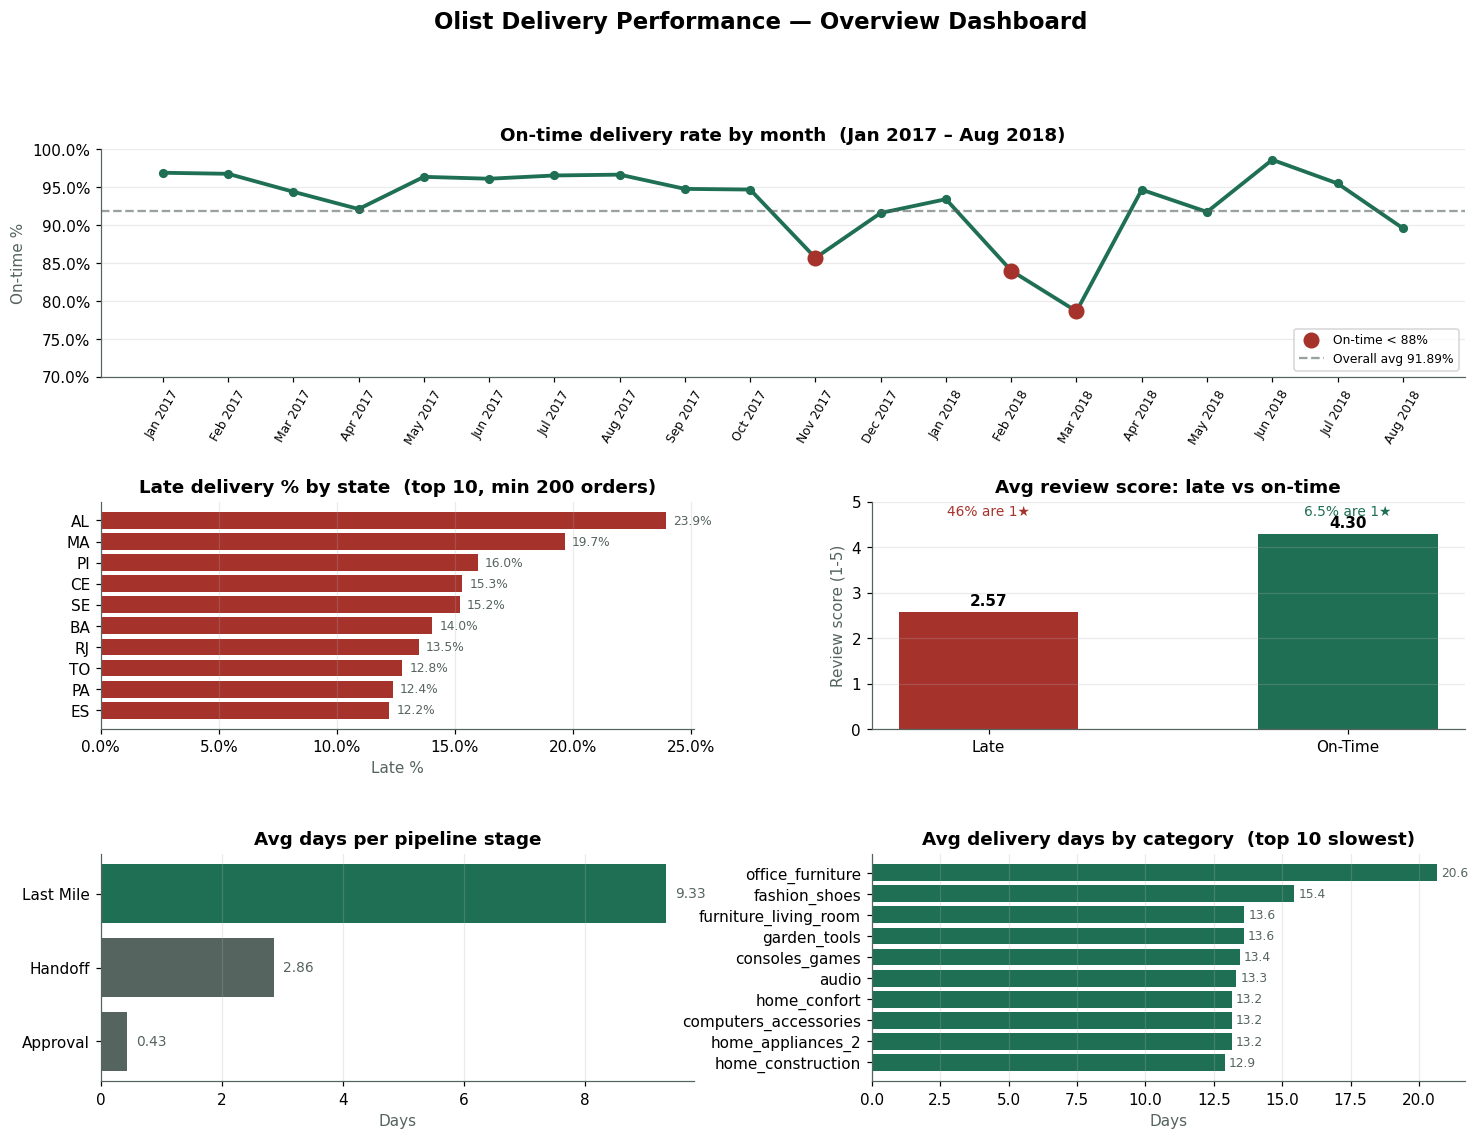


✅ Chart saved: /content/drive/MyDrive/olist-retention-project/outputs/figures/dashboard_overview.png


In [45]:
# =========================================================
# STEP 12B - Charts (matplotlib, styled)
# =========================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd

# ---- Style: match the client's example (green/white) ----
GREEN   = '#1f6f54'
RED     = '#a5322b'
GREY    = '#55645f'
LIGHT   = '#e6f2ec'

plt.rcParams.update({
    'figure.dpi': 110,
    'font.size': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': GREY,
    'axes.labelcolor': GREY,
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
})

fig = plt.figure(figsize=(16, 11))
gs = fig.add_gridspec(3, 2, hspace=0.55, wspace=0.30)

# ============ Chart 1: Monthly on-time trend ============
ax1 = fig.add_subplot(gs[0, :])
monthly['month_str'] = pd.to_datetime(monthly['month']).dt.strftime('%b %Y')
ax1.plot(monthly['month_str'], monthly['on_time_pct'],
         color=GREEN, linewidth=2.5, marker='o', markersize=5)
# Highlight the crisis months
crisis = monthly[monthly['on_time_pct'] < 88]
ax1.scatter(crisis['month_str'], crisis['on_time_pct'],
            color=RED, s=90, zorder=5, label='On-time < 88%')
ax1.axhline(91.89, color=GREY, linestyle='--', alpha=0.6,
            label='Overall avg 91.89%')
ax1.set_title('On-time delivery rate by month  (Jan 2017 – Aug 2018)')
ax1.set_ylabel('On-time %')
ax1.set_ylim(70, 100)
ax1.yaxis.set_major_formatter(mtick.PercentFormatter())
ax1.tick_params(axis='x', rotation=60, labelsize=8)
ax1.legend(loc='lower right', fontsize=8)
ax1.grid(alpha=0.25, axis='y')

# ============ Chart 2: Late % by state ============
ax2 = fig.add_subplot(gs[1, 0])
top10_states = states.head(10).iloc[::-1]   # reverse for horizontal
bars = ax2.barh(top10_states['state'], top10_states['late_pct'], color=RED)
ax2.set_title('Late delivery % by state  (top 10, min 200 orders)')
ax2.set_xlabel('Late %')
ax2.xaxis.set_major_formatter(mtick.PercentFormatter())
ax2.grid(alpha=0.25, axis='x')
for bar in bars:
    w = bar.get_width()
    ax2.text(w + 0.3, bar.get_y() + bar.get_height()/2,
             f'{w:.1f}%', va='center', fontsize=8, color=GREY)

# ============ Chart 3: Review score late vs on-time ============
ax3 = fig.add_subplot(gs[1, 1])
x = ['Late', 'On-Time']
scores = [2.566, 4.296]
bars = ax3.bar(x, scores, color=[RED, GREEN], width=0.5)
ax3.set_title('Avg review score: late vs on-time')
ax3.set_ylabel('Review score (1-5)')
ax3.set_ylim(0, 5)
ax3.grid(alpha=0.25, axis='y')
for bar, v in zip(bars, scores):
    ax3.text(bar.get_x() + bar.get_width()/2, v + 0.15,
             f'{v:.2f}', ha='center', fontweight='bold')
# Add the 1-star annotation
ax3.text(0, 4.7, '46% are 1★', ha='center', fontsize=9, color=RED)
ax3.text(1, 4.7, '6.5% are 1★', ha='center', fontsize=9, color=GREEN)

# ============ Chart 4: Stage durations ============
ax4 = fig.add_subplot(gs[2, 0])
stages_rev = stages.iloc[::-1]
bars = ax4.barh(stages_rev['stage'], stages_rev['avg_days'],
                color=[GREY, GREY, GREEN])
ax4.set_title('Avg days per pipeline stage')
ax4.set_xlabel('Days')
ax4.grid(alpha=0.25, axis='x')
for bar in bars:
    w = bar.get_width()
    ax4.text(w + 0.15, bar.get_y() + bar.get_height()/2,
             f'{w:.2f}', va='center', fontsize=9, color=GREY)

# ============ Chart 5: Top 10 slowest categories ============
ax5 = fig.add_subplot(gs[2, 1])
cats_rev = categories.iloc[::-1]
bars = ax5.barh(cats_rev['category'], cats_rev['avg_days'], color=GREEN)
ax5.set_title('Avg delivery days by category  (top 10 slowest)')
ax5.set_xlabel('Days')
ax5.grid(alpha=0.25, axis='x')
for bar in bars:
    w = bar.get_width()
    ax5.text(w + 0.15, bar.get_y() + bar.get_height()/2,
             f'{w:.1f}', va='center', fontsize=8, color=GREY)

fig.suptitle('Olist Delivery Performance — Overview Dashboard',
             fontsize=15, fontweight='bold', y=0.995)

# Save to outputs/figures/
out = '/content/drive/MyDrive/olist-retention-project/outputs/figures/dashboard_overview.png'
plt.savefig(out, dpi=120, bbox_inches='tight')
plt.show()
print(f"\n✅ Chart saved: {out}")

In [46]:
import os
decisions_path = "/content/drive/MyDrive/olist-retention-project/docs/DECISIONS.md"
with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

content = content.rstrip() + """

**Finding 6 (discovered in chart):** On-time rate has three notable dips:
Nov 2017 (85.7%, Black Friday volume spike), Feb 2018 (84.0%), Mar 2018 (78.6%, worst month).
Recovery by Apr 2018. Best month Jun 2018 (98.6%). Cause not provable with current data.
"""
with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print("✅ Finding 6 logged. Size:", os.path.getsize(decisions_path), "bytes")

✅ Finding 6 logged. Size: 15122 bytes


In [47]:
# =========================================================
# STEP 12C - Build Excel workbook
# =========================================================
import pandas as pd
import sqlite3
import os
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils.dataframe import dataframe_to_rows
from openpyxl.drawing.image import Image as XLImage

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
OUT_PATH = "/content/drive/MyDrive/olist-retention-project/outputs/reports/olist_delivery_report.xlsx"
IMG_PATH = "/content/drive/MyDrive/olist-retention-project/outputs/figures/dashboard_overview.png"

os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
con = sqlite3.connect(DB_PATH)

# ---- Styling constants ----
GREEN = "1F6F54"
LIGHT_GREEN = "E6F2EC"
GREY  = "55645F"
WHITE = "FFFFFF"

title_font   = Font(name="Calibri", size=16, bold=True, color=GREEN)
head_font    = Font(name="Calibri", size=11, bold=True, color=WHITE)
body_font    = Font(name="Calibri", size=11)
big_font     = Font(name="Calibri", size=24, bold=True, color=GREEN)
kpi_label    = Font(name="Calibri", size=10, color=GREY)

head_fill    = PatternFill("solid", fgColor=GREEN)
light_fill   = PatternFill("solid", fgColor=LIGHT_GREEN)
thin         = Side(border_style="thin", color="CCCCCC")
border       = Border(left=thin, right=thin, top=thin, bottom=thin)
center       = Alignment(horizontal="center", vertical="center")

wb = Workbook()

# ============ SHEET 1: KPI Overview ============
ws = wb.active
ws.title = "Overview"
ws["A1"] = "Olist Delivery Performance — Overview"
ws["A1"].font = title_font
ws.merge_cells("A1:F1")

# KPI cards
kpi_data = [
    ("Total Orders", "96,476", GREEN),
    ("On-Time Rate", "91.89%", GREEN),
    ("Late Orders",  "7,827",  "A5322B"),
    ("Avg Delivery Days", "12.56", GREY),
    ("Late Review Score", "2.57", "A5322B"),
    ("On-Time Review Score", "4.30", GREEN),
]
for i, (label, value, color) in enumerate(kpi_data):
    col = i + 1
    ws.cell(row=3, column=col, value=label).font = kpi_label
    ws.cell(row=4, column=col, value=value).font = Font(name="Calibri", size=20, bold=True, color=color)
    ws.cell(row=3, column=col).alignment = center
    ws.cell(row=4, column=col).alignment = center
    ws.cell(row=3, column=col).fill = light_fill
    ws.cell(row=4, column=col).fill = light_fill

# Embed the dashboard image
img = XLImage(IMG_PATH)
img.width = 1100
img.height = 750
ws.add_image(img, "A6")

# ============ SHEET 2: States ============
ws2 = wb.create_sheet("By State")
ws2["A1"] = "Delivery performance by customer state"
ws2["A1"].font = title_font

states_df = pd.read_sql_query("""
    SELECT c.customer_state AS state,
           COUNT(*) AS orders,
           SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) AS late_orders,
           ROUND(100.0 * SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct,
           ROUND(AVG(o.delivery_days), 2) AS avg_delivery_days
    FROM orders o
    JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.is_late IS NOT NULL
    GROUP BY state
    HAVING COUNT(*) >= 200
    ORDER BY late_pct DESC
""", con)

for r_idx, row in enumerate(dataframe_to_rows(states_df, index=False, header=True), start=3):
    for c_idx, val in enumerate(row, start=1):
        cell = ws2.cell(row=r_idx, column=c_idx, value=val)
        cell.border = border
        if r_idx == 3:
            cell.font = head_font
            cell.fill = head_fill
            cell.alignment = center
        else:
            cell.font = body_font

# ============ SHEET 3: Categories ============
ws3 = wb.create_sheet("By Category")
ws3["A1"] = "Delivery performance by product category"
ws3["A1"].font = title_font

cats_df = pd.read_sql_query("""
    SELECT COALESCE(ct.product_category_name_english, p.product_category_name) AS category,
           COUNT(DISTINCT o.order_id) AS orders,
           ROUND(AVG(o.delivery_days), 2) AS avg_delivery_days,
           ROUND(AVG(o.lateness_days), 2) AS avg_lateness_days
    FROM orders o
    JOIN order_items i ON i.order_id = o.order_id
    JOIN products p    ON p.product_id = i.product_id
    LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
    WHERE o.delivery_days IS NOT NULL AND o.migration_artifact = 0
    GROUP BY category
    HAVING COUNT(DISTINCT o.order_id) >= 200
    ORDER BY avg_delivery_days DESC
""", con)

for r_idx, row in enumerate(dataframe_to_rows(cats_df, index=False, header=True), start=3):
    for c_idx, val in enumerate(row, start=1):
        cell = ws3.cell(row=r_idx, column=c_idx, value=val)
        cell.border = border
        if r_idx == 3:
            cell.font = head_font
            cell.fill = head_fill
            cell.alignment = center
        else:
            cell.font = body_font

# ============ SHEET 4: Monthly Trend ============
ws4 = wb.create_sheet("Monthly Trend")
ws4["A1"] = "On-time delivery rate by month"
ws4["A1"].font = title_font

monthly_df = pd.read_sql_query("""
    SELECT strftime('%Y-%m', order_purchase_timestamp) AS month,
           COUNT(*) AS orders,
           ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct
    FROM orders
    WHERE is_late IS NOT NULL
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp < '2018-09-01'
    GROUP BY month ORDER BY month
""", con)

for r_idx, row in enumerate(dataframe_to_rows(monthly_df, index=False, header=True), start=3):
    for c_idx, val in enumerate(row, start=1):
        cell = ws4.cell(row=r_idx, column=c_idx, value=val)
        cell.border = border
        if r_idx == 3:
            cell.font = head_font
            cell.fill = head_fill
            cell.alignment = center
        else:
            cell.font = body_font

# ============ SHEET 5: Data Quality Log ============
ws5 = wb.create_sheet("Data Quality")
ws5["A1"] = "Data quality log"
ws5["A1"].font = title_font

dq_rows = [
    ["Issue", "Rows", "Action"],
    ["Missing delivery date (undelivered)", 2965, "Filtered out (universe = delivered only)"],
    ["Duplicate review_ids", 814, "Deduplicated — kept 1 per review_id"],
    ["Duplicate order_ids in reviews", 314, "Deduplicated — kept latest review_creation_date"],
    ["Missing product_category_name", 610, "Relabelled as 'unknown_category'"],
    ["carrier_date < approved_at (timezone)", 621, "Kept — flagged as sequence_anomaly"],
    ["carrier_date < approved_at (>6h)", 738, "Kept — flagged as sequence_anomaly"],
    ["carrier_date < approved_at (>7d)", 14, "Kept — flagged as sequence_anomaly_severe"],
    ["Impossible deliveries", 23, "Kept — flagged; excluded from time KPIs"],
    ["Zero-weight products", 4, "Kept — no action"],
    ["Migration artifacts (last_mile > 90d)", 71, "Kept — flagged as migration_artifact"],
]
for r_idx, row in enumerate(dq_rows, start=3):
    for c_idx, val in enumerate(row, start=1):
        cell = ws5.cell(row=r_idx, column=c_idx, value=val)
        cell.border = border
        if r_idx == 3:
            cell.font = head_font
            cell.fill = head_fill
            cell.alignment = center
        else:
            cell.font = body_font

# ============ SHEET 6: Definitions ============
ws6 = wb.create_sheet("Definitions")
ws6["A1"] = "KPI definitions"
ws6["A1"].font = title_font

defs = [
    ["KPI", "Formula", "Grain"],
    ["On-Time Rate", "on-time orders / delivered orders (is_late = 0)", "order"],
    ["Delivery Days", "delivered_customer_date - order_purchase_timestamp", "order"],
    ["Lateness Days", "delivered_customer_date - estimated_delivery_date", "order"],
    ["Approval Days", "approved_at - purchase_timestamp", "order"],
    ["Handoff Days", "carrier_date - approved_at", "order"],
    ["Last Mile Days", "delivered_customer_date - carrier_date", "order"],
    ["Review Avg", "AVG(review_score)", "order"],
    ["Universe", "order_status = 'delivered' AND delivery_date IS NOT NULL", "order"],
    ["Analysis window", "2017-01-01 to 2018-08-31", "—"],
]
for r_idx, row in enumerate(defs, start=3):
    for c_idx, val in enumerate(row, start=1):
        cell = ws6.cell(row=r_idx, column=c_idx, value=val)
        cell.border = border
        if r_idx == 3:
            cell.font = head_font
            cell.fill = head_fill
            cell.alignment = center
        else:
            cell.font = body_font

# ---- Column widths ----
for ws in [ws2, ws3, ws4, ws5, ws6]:
    for col in ws.columns:
        max_len = max((len(str(c.value)) for c in col if c.value), default=10)
        ws.column_dimensions[col[0].column_letter].width = min(max_len + 3, 50)

# ---- Freeze top rows ----
for ws in [ws2, ws3, ws4, ws5, ws6]:
    ws.freeze_panes = "A4"

wb.save(OUT_PATH)
con.close()
print(f"✅ Excel workbook saved: {OUT_PATH}")
print(f"   Size: {os.path.getsize(OUT_PATH) / 1024:.1f} KB")

✅ Excel workbook saved: /content/drive/MyDrive/olist-retention-project/outputs/reports/olist_delivery_report.xlsx
   Size: 186.3 KB


In [60]:
# =========================================================
# STEP 12E (v2) - HIGH-RES chart PNGs (300 DPI, larger figures)
# =========================================================
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import pandas as pd
import sqlite3
import os

DB_PATH = "/content/drive/MyDrive/olist-retention-project/data/processed/project.db"
FIG_DIR = "/content/drive/MyDrive/olist-retention-project/outputs/figures"
os.makedirs(FIG_DIR, exist_ok=True)
con = sqlite3.connect(DB_PATH)

GREEN = '#1f6f54'
RED   = '#a5322b'
GREY  = '#55645f'

plt.rcParams.update({
    'figure.dpi': 300,            # ← 300 DPI = print-quality
    'savefig.dpi': 300,
    'font.size': 13,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.edgecolor': '#cbd5cc',
    'axes.labelcolor': GREY,
    'xtick.color': GREY,
    'ytick.color': GREY,
    'axes.grid': True,
    'grid.color': '#e3e9e2',
    'grid.linewidth': 1.0,
})

# ---- 1. Monthly trend (WIDE) ----
monthly = pd.read_sql_query("""
    SELECT strftime('%Y-%m', order_purchase_timestamp) AS month,
           ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct
    FROM orders
    WHERE is_late IS NOT NULL
      AND order_purchase_timestamp >= '2017-01-01'
      AND order_purchase_timestamp < '2018-09-01'
    GROUP BY month ORDER BY month
""", con)
fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(monthly['month'], monthly['on_time_pct'], color=GREEN, linewidth=3,
        marker='o', markersize=8, markerfacecolor='white', markeredgewidth=2.5)
ax.fill_between(range(len(monthly)), monthly['on_time_pct'], alpha=0.10, color=GREEN)
ax.axhline(91.89, color=GREY, linestyle='--', alpha=0.5, linewidth=1.2)
ax.set_ylim(70, 100)
ax.yaxis.set_major_formatter(mtick.PercentFormatter())
ax.set_title('On-time delivery rate by month', fontsize=16, fontweight='bold',
             color='#1c2a27', loc='left', pad=16)
ax.tick_params(axis='x', rotation=55, labelsize=10)
plt.xticks(range(len(monthly)), monthly['month'])
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart_monthly.png", bbox_inches='tight', facecolor='white')
plt.close()

# ---- 2. Late % by state ----
states = pd.read_sql_query("""
    SELECT c.customer_state AS state,
           ROUND(100.0 * SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
    FROM orders o JOIN customers c ON c.customer_id = o.customer_id
    WHERE o.is_late IS NOT NULL
    GROUP BY state HAVING COUNT(*) >= 200
    ORDER BY late_pct DESC LIMIT 10
""", con).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(states['state'], states['late_pct'], color=RED, height=0.72)
for b, v in zip(bars, states['late_pct']):
    ax.text(b.get_width() + 0.4, b.get_y() + b.get_height()/2,
            f'{v:.1f}%', va='center', fontsize=11, color=GREY, fontweight='bold')
ax.set_xlim(0, 28)
ax.set_title('Late % by state (top 10)', fontsize=16, fontweight='bold',
             color='#1c2a27', loc='left', pad=16)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart_states.png", bbox_inches='tight', facecolor='white')
plt.close()

# ---- 3. Review score comparison ----
review = pd.read_sql_query("""
    SELECT CASE WHEN o.is_late = 1 THEN 'Late' ELSE 'On-Time' END AS status,
           ROUND(AVG(r.review_score), 3) AS avg_score
    FROM orders o JOIN order_reviews r ON r.order_id = o.order_id
    WHERE o.is_late IS NOT NULL
    GROUP BY status
""", con)
fig, ax = plt.subplots(figsize=(8, 6))
colors = [RED if s == 'Late' else GREEN for s in review['status']]
bars = ax.bar(review['status'], review['avg_score'], color=colors, width=0.55)
for b, v in zip(bars, review['avg_score']):
    ax.text(b.get_x() + b.get_width()/2, v + 0.15, f'{v:.2f}',
            ha='center', fontsize=15, fontweight='bold', color=GREY)
ax.text(0, 4.75, '46% are 1★', ha='center', fontsize=12, color=RED, fontweight='bold')
ax.text(1, 4.75, '6.5% are 1★', ha='center', fontsize=12, color=GREEN, fontweight='bold')
ax.set_ylim(0, 5)
ax.set_title('Avg review score: late vs on-time', fontsize=16, fontweight='bold',
             color='#1c2a27', loc='left', pad=16)
ax.grid(axis='x', visible=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart_review.png", bbox_inches='tight', facecolor='white')
plt.close()

# ---- 4. Pipeline stages ----
stages = pd.DataFrame({'stage': ['Last Mile', 'Handoff', 'Approval'],
                       'days': [9.334, 2.859, 0.434]})
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(stages['stage'], stages['days'],
               color=[GREEN, '#8a9a94', '#cbd5cc'], height=0.62)
for b, v in zip(bars, stages['days']):
    ax.text(b.get_width() + 0.15, b.get_y() + b.get_height()/2,
            f'{v:.2f}', va='center', fontsize=13, color=GREY, fontweight='bold')
ax.set_xlim(0, 11)
ax.set_title('Avg days per pipeline stage', fontsize=16, fontweight='bold',
             color='#1c2a27', loc='left', pad=16)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart_stages.png", bbox_inches='tight', facecolor='white')
plt.close()

# ---- 5. Top categories ----
cats = pd.read_sql_query("""
    SELECT COALESCE(ct.product_category_name_english, p.product_category_name) AS category,
           ROUND(AVG(o.delivery_days), 2) AS avg_days
    FROM orders o
    JOIN order_items i ON i.order_id = o.order_id
    JOIN products p    ON p.product_id = i.product_id
    LEFT JOIN category_translation ct ON ct.product_category_name = p.product_category_name
    WHERE o.delivery_days IS NOT NULL AND o.migration_artifact = 0
    GROUP BY category HAVING COUNT(DISTINCT o.order_id) >= 200
    ORDER BY avg_days DESC LIMIT 10
""", con).iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.barh(cats['category'], cats['avg_days'], color=GREEN, height=0.72)
for b, v in zip(bars, cats['avg_days']):
    ax.text(b.get_width() + 0.15, b.get_y() + b.get_height()/2,
            f'{v:.1f}', va='center', fontsize=11, color=GREY, fontweight='bold')
ax.set_xlim(0, 24)
ax.set_title('Avg delivery days by category (top 10)', fontsize=16, fontweight='bold',
             color='#1c2a27', loc='left', pad=16)
ax.grid(axis='y', visible=False)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/chart_categories.png", bbox_inches='tight', facecolor='white')
plt.close()

con.close()
print("✅ 5 high-res charts regenerated (300 DPI)")
for f in sorted(os.listdir(FIG_DIR)):
    if f.startswith('chart_'):
        size_kb = os.path.getsize(f"{FIG_DIR}/{f}") / 1024
        print(f"   {f}  ({size_kb:.0f} KB)")

✅ 5 high-res charts regenerated (300 DPI)
   chart_categories.png  (171 KB)
   chart_monthly.png  (222 KB)
   chart_review.png  (74 KB)
   chart_stages.png  (76 KB)
   chart_states.png  (107 KB)


In [61]:
# =========================================================
# STEP 12F (v5) - HTML, fixed sizing
# =========================================================
import base64, os

FIG_DIR  = "/content/drive/MyDrive/olist-retention-project/outputs/figures"
OUT_HTML = "/content/drive/MyDrive/olist-retention-project/outputs/reports/olist_dashboard.html"

def b64(path):
    with open(path, 'rb') as f:
        return base64.b64encode(f.read()).decode()

img_monthly    = b64(f"{FIG_DIR}/chart_monthly.png")
img_states     = b64(f"{FIG_DIR}/chart_states.png")
img_review     = b64(f"{FIG_DIR}/chart_review.png")
img_stages     = b64(f"{FIG_DIR}/chart_stages.png")
img_categories = b64(f"{FIG_DIR}/chart_categories.png")

html = """<!DOCTYPE html>
<html lang="en">
<head>
<meta charset="UTF-8">
<meta name="viewport" content="width=device-width, initial-scale=1.0">
<title>Olist Delivery Performance — Analytics Dashboard</title>
<link rel="preconnect" href="https://fonts.googleapis.com">
<link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
<link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700;800;900&display=swap" rel="stylesheet">
<style>
  :root {
    --green: #1f6f54; --green-bright: #2d9974; --green-dark: #145038;
    --navy: #1b4965; --ink: #0f1a17; --muted: #55645f;
    --rule: #e3e9e2; --bg: #f3f5ef; --card: #ffffff;
  }
  * { box-sizing: border-box; margin: 0; padding: 0; }
  html { scroll-behavior: smooth; scroll-padding-top: 24px; }
  body {
    font-family: 'Inter', -apple-system, "Segoe UI", Roboto, sans-serif;
    background: var(--bg); color: var(--ink);
    min-height: 100vh; -webkit-font-smoothing: antialiased;
    overflow-x: hidden;
  }

  .progress-bar {
    position: fixed; top: 0; left: 0; height: 3px; width: 0%;
    background: linear-gradient(90deg, var(--navy), var(--green), var(--green-bright), var(--green));
    background-size: 300% 100%;
    animation: gradientShift 4s ease infinite;
    z-index: 100; transition: width 0.1s linear;
    box-shadow: 0 0 12px rgba(45,153,116,0.5);
  }
  @keyframes gradientShift {
    0%,100% { background-position: 0% 50%; }
    50%     { background-position: 100% 50%; }
  }

  /* Sidebar */
  .sidebar {
    width: 84px;
    background: linear-gradient(180deg, var(--navy) 0%, var(--green-dark) 70%, var(--green) 100%);
    display: flex; flex-direction: column; align-items: center;
    padding: 26px 0; gap: 6px;
    position: fixed; height: 100vh; left: 0; top: 0;
    box-shadow: 4px 0 24px rgba(0,0,0,0.10); z-index: 10;
  }
  .sidebar .logo {
    width: 48px; height: 48px;
    background: linear-gradient(135deg, #ffffff, #e6f2ec);
    border-radius: 14px;
    display: flex; align-items: center; justify-content: center;
    font-weight: 900; color: var(--green); font-size: 24px;
    margin-bottom: 26px;
    box-shadow: 0 6px 18px rgba(0,0,0,0.20);
    animation: logoIn 0.9s cubic-bezier(0.34, 1.56, 0.64, 1);
    cursor: pointer; border: none;
    transition: transform 0.3s ease;
  }
  .sidebar .logo:hover { transform: rotate(-8deg) scale(1.08); }
  @keyframes logoIn {
    0%   { transform: scale(0) rotate(-180deg); opacity: 0; }
    100% { transform: scale(1) rotate(0deg); opacity: 1; }
  }

  .nav-btn {
    width: 48px; height: 48px;
    display: flex; align-items: center; justify-content: center;
    border-radius: 12px;
    color: rgba(255,255,255,0.55);
    cursor: pointer;
    transition: all 0.25s cubic-bezier(0.34, 1.56, 0.64, 1);
    position: relative; overflow: hidden;
    text-decoration: none; background: transparent;
    border: none; font-family: inherit;
  }
  .nav-btn:hover {
    background: rgba(255,255,255,0.14); color: white;
    transform: translateY(-2px) scale(1.05);
  }
  .nav-btn.active {
    background: rgba(255,255,255,0.22); color: white;
    box-shadow: inset 0 0 0 2px rgba(255,255,255,0.30), 0 4px 12px rgba(0,0,0,0.15);
  }
  .nav-btn.active::before {
    content: '';
    position: absolute; left: -8px; top: 50%;
    width: 4px; height: 26px; margin-top: -13px;
    background: white; border-radius: 2px;
    animation: navPulse 1.8s ease-in-out infinite;
  }
  @keyframes navPulse {
    0%,100% { opacity: 0.6; transform: scaleY(1); }
    50%     { opacity: 1;   transform: scaleY(1.2); }
  }
  .nav-btn svg { width: 22px; height: 22px; position: relative; z-index: 1; }
  .nav-btn .ripple {
    position: absolute; border-radius: 50%;
    background: rgba(255,255,255,0.5);
    transform: scale(0); animation: ripple 0.6s linear;
    pointer-events: none;
  }
  @keyframes ripple { to { transform: scale(4); opacity: 0; } }
  .nav-spacer { flex: 1; }

  /* Main */
  .main {
    margin-left: 84px;
    padding: 28px 40px 60px;
    max-width: 1400px;
  }

  /* Topbar */
  .topbar {
    display: flex; justify-content: space-between; align-items: flex-end;
    margin-bottom: 26px; padding-bottom: 20px;
    border-bottom: 2px solid var(--rule);
    animation: slideDown 0.7s cubic-bezier(0.22, 1, 0.36, 1);
  }
  @keyframes slideDown {
    from { opacity: 0; transform: translateY(-16px); }
    to   { opacity: 1; transform: translateY(0); }
  }
  .topbar h1 {
    font-size: 30px; font-weight: 900;
    letter-spacing: -0.025em; color: var(--ink); line-height: 1.15;
  }
  .topbar h1 span {
    background: linear-gradient(120deg, var(--green) 30%, var(--green-bright) 60%, var(--navy) 100%);
    background-size: 200% auto;
    -webkit-background-clip: text; -webkit-text-fill-color: transparent;
    background-clip: text; animation: gradientText 4s ease infinite;
  }
  @keyframes gradientText {
    0%,100% { background-position: 0% center; }
    50%     { background-position: 100% center; }
  }
  .topbar .sub {
    font-size: 13px; color: var(--muted); margin-top: 8px; font-weight: 500;
  }
  .brand {
    text-align: right; font-size: 12px; color: var(--muted); line-height: 1.5;
  }
  .brand strong {
    display: block; font-size: 15px; color: var(--green);
    font-weight: 800; margin-bottom: 2px;
  }
  .live-clock {
    display: inline-flex; align-items: center; gap: 6px;
    margin-top: 8px; font-size: 11px; color: var(--muted); font-weight: 600;
  }
  .live-clock .dot {
    width: 7px; height: 7px; border-radius: 50%; background: #2d9974;
    animation: pulseDot 2s infinite;
  }
  @keyframes pulseDot {
    0%   { box-shadow: 0 0 0 0 rgba(45,153,116,0.7); }
    70%  { box-shadow: 0 0 0 8px rgba(45,153,116,0); }
    100% { box-shadow: 0 0 0 0 rgba(45,153,116,0); }
  }

  /* KPI grid */
  .kpi-grid {
    display: grid;
    grid-template-columns: repeat(6, 1fr);
    gap: 16px; margin-bottom: 30px;
  }
  @media (max-width: 1280px) { .kpi-grid { grid-template-columns: repeat(3, 1fr); } }

  .kpi {
    padding: 20px 18px; border-radius: 16px;
    position: relative; overflow: hidden;
    border: 1px solid rgba(0,0,0,0.04);
    animation: cardIn 0.7s cubic-bezier(0.22, 1, 0.36, 1) backwards;
    transition: transform 0.3s cubic-bezier(0.34, 1.56, 0.64, 1), box-shadow 0.3s ease;
  }
  .kpi:nth-child(1) { animation-delay: 0.05s; }
  .kpi:nth-child(2) { animation-delay: 0.10s; }
  .kpi:nth-child(3) { animation-delay: 0.15s; }
  .kpi:nth-child(4) { animation-delay: 0.20s; }
  .kpi:nth-child(5) { animation-delay: 0.25s; }
  .kpi:nth-child(6) { animation-delay: 0.30s; }
  @keyframes cardIn {
    from { opacity: 0; transform: translateY(24px) scale(0.96); }
    to   { opacity: 1; transform: translateY(0) scale(1); }
  }
  .kpi::before {
    content: '';
    position: absolute;
    top: 0; left: -100%; width: 100%; height: 100%;
    background: linear-gradient(90deg, transparent, rgba(255,255,255,0.6), transparent);
    transition: left 0.8s ease;
  }
  .kpi:hover::before { left: 100%; }
  .kpi:hover {
    transform: translateY(-5px) scale(1.02);
    box-shadow: 0 16px 36px rgba(0,0,0,0.12);
  }
  .kpi .icon {
    position: absolute; top: 16px; right: 16px;
    width: 24px; height: 24px; opacity: 0.4;
    transition: all 0.3s ease;
  }
  .kpi:hover .icon { opacity: 0.9; transform: rotate(8deg) scale(1.1); }
  .kpi .label {
    font-size: 10.5px; font-weight: 700; color: var(--muted);
    text-transform: uppercase; letter-spacing: 0.08em; margin-bottom: 12px;
    position: relative; z-index: 1;
  }
  .kpi .value {
    font-size: 30px; font-weight: 900; line-height: 1;
    letter-spacing: -0.03em; font-variant-numeric: tabular-nums;
    position: relative; z-index: 1;
  }
  .kpi.pink   { background: linear-gradient(135deg,#fbe9ec,#f5d8dd); } .kpi.pink   .value { color: #a5322b; }
  .kpi.green  { background: linear-gradient(135deg,#e6f2ec,#d5ebe0); } .kpi.green  .value { color: var(--green); }
  .kpi.purple { background: linear-gradient(135deg,#ede9f5,#e1daf0); } .kpi.purple .value { color: #5c4b8a; }
  .kpi.yellow { background: linear-gradient(135deg,#fbf0dc,#f6e6c6); } .kpi.yellow .value { color: #8f5509; }
  .kpi.blue   { background: linear-gradient(135deg,#e3edf7,#d2e2f2); } .kpi.blue   .value { color: #2c5f8a; }
  .kpi.mint   { background: linear-gradient(135deg,#e0f2ec,#cbe9dd); } .kpi.mint   .value { color: var(--green); }

  /* Sections */
  .section { padding-top: 12px; margin-bottom: 26px; }
  .section-head {
    display: flex; align-items: center; gap: 14px;
    margin: 12px 0 16px;
    opacity: 0; transform: translateX(-24px);
    transition: all 0.7s cubic-bezier(0.22, 1, 0.36, 1);
  }
  .section-head.visible { opacity: 1; transform: translateX(0); }
  .section-head .bar {
    width: 4px; height: 28px; border-radius: 2px;
    background: linear-gradient(180deg, var(--green), var(--navy));
  }
  .section-head h2 {
    font-size: 18px; font-weight: 800; color: var(--ink);
    letter-spacing: -0.02em;
  }
  .section-head .hint {
    margin-left: auto; font-size: 11px; color: var(--muted);
    font-weight: 600; text-transform: uppercase; letter-spacing: 0.08em;
  }

  /* Chart grid: 2x2 for the small charts, full-width for monthly */
  .chart-grid {
    display: grid;
    grid-template-columns: 1fr 1fr;
    gap: 22px;
  }
  @media (max-width: 900px) {
    .chart-grid { grid-template-columns: 1fr; }
  }
  .card {
    background: var(--card);
    border-radius: 18px;
    padding: 20px;
    box-shadow: 0 1px 3px rgba(0,0,0,0.04), 0 6px 24px rgba(0,0,0,0.04);
    transition: transform 0.35s cubic-bezier(0.22, 1, 0.36, 1), box-shadow 0.35s ease;
    opacity: 0;
    transform: translateY(28px) scale(0.98);
    overflow: hidden;
    position: relative;
    display: flex; align-items: center; justify-content: center;
  }
  .card.visible { opacity: 1; transform: translateY(0) scale(1); }
  .card:hover {
    transform: translateY(-4px) scale(1.005);
    box-shadow: 0 20px 48px rgba(0,0,0,0.10);
  }
  .card.wide { grid-column: 1 / -1; }

  /* THE KEY FIX: images keep aspect ratio, cap height, no stretching */
  .card img {
    display: block;
    width: 100%;
    height: auto;
    max-height: 480px;             /* prevents giant stretching */
    object-fit: contain;            /* letterbox rather than stretch */
    border-radius: 8px;
  }
  .card.wide img {
    max-height: 420px;              /* wide charts shouldn't be too tall */
  }

  .card::after {
    content: '';
    position: absolute;
    top: 0; left: 0; right: 0; height: 3px;
    background: linear-gradient(90deg, var(--green), var(--green-bright), var(--navy));
    transform: scaleX(0); transform-origin: left;
    transition: transform 0.5s ease;
  }
  .card.visible::after { transform: scaleX(1); }

  /* Footer */
  .footer {
    margin-top: 40px; padding-top: 24px;
    border-top: 1px solid var(--rule);
    text-align: center; font-size: 12px; color: var(--muted);
    opacity: 0; animation: cardIn 0.9s ease-out 1.2s forwards;
  }
  .footer strong { color: var(--green); font-weight: 700; }

  /* Back to top */
  .back-top {
    position: fixed; right: 28px; bottom: 28px;
    width: 48px; height: 48px; border-radius: 50%;
    background: var(--green); color: white;
    display: flex; align-items: center; justify-content: center;
    cursor: pointer; opacity: 0;
    transform: translateY(20px) scale(0.8);
    transition: all 0.4s cubic-bezier(0.34, 1.56, 0.64, 1);
    box-shadow: 0 8px 24px rgba(31,111,84,0.35);
    z-index: 20; border: none;
  }
  .back-top.show { opacity: 1; transform: translateY(0) scale(1); }
  .back-top:hover { transform: translateY(-3px) scale(1.08); }
  .back-top svg { width: 22px; height: 22px; }

  /* Info modal */
  .modal-backdrop {
    position: fixed; inset: 0;
    background: rgba(15, 26, 23, 0.5);
    backdrop-filter: blur(4px);
    -webkit-backdrop-filter: blur(4px);
    z-index: 50; opacity: 0; pointer-events: none;
    transition: opacity 0.3s ease;
  }
  .modal-backdrop.show { opacity: 1; pointer-events: auto; }
  .modal {
    position: fixed; top: 50%; left: 50%;
    transform: translate(-50%, -45%) scale(0.95);
    width: min(560px, 92vw); max-height: 80vh; overflow-y: auto;
    background: white; border-radius: 20px; padding: 32px;
    box-shadow: 0 24px 64px rgba(0,0,0,0.25);
    z-index: 51; opacity: 0; pointer-events: none;
    transition: all 0.35s cubic-bezier(0.34, 1.56, 0.64, 1);
  }
  .modal.show {
    opacity: 1; pointer-events: auto;
    transform: translate(-50%, -50%) scale(1);
  }
  .modal h3 { font-size: 20px; font-weight: 800; color: var(--green); margin-bottom: 6px; }
  .modal .modal-sub { font-size: 12px; color: var(--muted); margin-bottom: 20px; font-weight: 500; }
  .modal p { font-size: 14px; line-height: 1.65; color: #2d3d39; margin-bottom: 14px; }
  .modal strong { color: var(--green); font-weight: 700; }
  .modal hr { border: none; border-top: 1px solid var(--rule); margin: 18px 0; }
  .modal .close-btn {
    position: absolute; top: 18px; right: 18px;
    width: 34px; height: 34px; border-radius: 50%;
    background: #f3f5ef; border: none;
    display: flex; align-items: center; justify-content: center;
    cursor: pointer; transition: all 0.2s ease; color: var(--muted);
  }
  .modal .close-btn:hover { background: #e3e9e2; color: var(--ink); transform: rotate(90deg); }
  .modal .close-btn svg { width: 16px; height: 16px; }
</style>
</head>
<body>

<div class="progress-bar" id="progressBar"></div>

<aside class="sidebar">
  <button class="logo" onclick="window.scrollTo({top:0,behavior:'smooth'})">O</button>
  <a class="nav-btn" href="#top" data-target="top" title="Overview">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><rect x="3" y="3" width="7" height="9" rx="1"/><rect x="14" y="3" width="7" height="5" rx="1"/><rect x="14" y="12" width="7" height="9" rx="1"/><rect x="3" y="16" width="7" height="5" rx="1"/></svg>
  </a>
  <a class="nav-btn" href="#trends" data-target="trends" title="Trends">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><polyline points="3 17 9 11 13 15 21 7"/><polyline points="15 7 21 7 21 13"/></svg>
  </a>
  <a class="nav-btn" href="#regions" data-target="regions" title="Regions">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><circle cx="12" cy="12" r="9"/><path d="M3 12h18M12 3a15 15 0 010 18M12 3a15 15 0 000 18"/></svg>
  </a>
  <a class="nav-btn" href="#satisfaction" data-target="satisfaction" title="Satisfaction">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><path d="M12 2l2.9 6.3L22 9.3l-5 4.8L18.2 22 12 18.6 5.8 22 7 14.1 2 9.3l7.1-1z"/></svg>
  </a>
  <a class="nav-btn" href="#pipeline" data-target="pipeline" title="Pipeline">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><path d="M3 7l9-4 9 4-9 4-9-4z"/><path d="M3 7v10l9 4 9-4V7"/></svg>
  </a>
  <a class="nav-btn" href="#products" data-target="products" title="Products">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><circle cx="9" cy="21" r="1"/><circle cx="20" cy="21" r="1"/><path d="M1 1h4l2.7 13.4a2 2 0 002 1.6h9.7a2 2 0 002-1.6L23 6H6"/></svg>
  </a>
  <div class="nav-spacer"></div>
  <button class="nav-btn" id="infoBtn" title="About this report">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2" stroke-linecap="round" stroke-linejoin="round"><circle cx="12" cy="12" r="10"/><line x1="12" y1="16" x2="12" y2="12"/><line x1="12" y1="8" x2="12.01" y2="8"/></svg>
  </button>
</aside>

<main class="main">
  <div id="top"></div>

  <div class="topbar">
    <div>
      <h1>Olist <span>Delivery Performance</span></h1>
      <div class="sub">On-time rate · Regional bottlenecks · Customer satisfaction</div>
    </div>
    <div class="brand">
      <strong>Analytics Report</strong>
      Simulated case study · Jan 2017 – Aug 2018
      <div class="live-clock"><span class="dot"></span><span id="clock">loading…</span></div>
    </div>
  </div>

  <div class="kpi-grid">
    <div class="kpi blue">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><path d="M21 16V8a2 2 0 00-1-1.7l-7-4a2 2 0 00-2 0l-7 4A2 2 0 003 8v8a2 2 0 001 1.7l7 4a2 2 0 002 0l7-4A2 2 0 0021 16z"/></svg></div>
      <div class="label">Total Orders</div>
      <div class="value" data-count="96476">0</div>
    </div>
    <div class="kpi green">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><path d="M20 6L9 17l-5-5"/></svg></div>
      <div class="label">On-Time Rate</div>
      <div class="value" data-count="91.89" data-suffix="%" data-decimals="2">0</div>
    </div>
    <div class="kpi pink">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><circle cx="12" cy="12" r="10"/><line x1="12" y1="8" x2="12" y2="12"/><line x1="12" y1="16" x2="12.01" y2="16"/></svg></div>
      <div class="label">Late Orders</div>
      <div class="value" data-count="7827">0</div>
    </div>
    <div class="kpi purple">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><circle cx="12" cy="12" r="10"/><polyline points="12 6 12 12 16 14"/></svg></div>
      <div class="label">Avg Delivery Days</div>
      <div class="value" data-count="12.6" data-decimals="1">0</div>
    </div>
    <div class="kpi yellow">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><path d="M12 2l2.9 6.3L22 9.3l-5 4.8L18.2 22 12 18.6 5.8 22 7 14.1 2 9.3l7.1-1z"/></svg></div>
      <div class="label">Late Review Score</div>
      <div class="value" data-count="2.57" data-decimals="2">0</div>
    </div>
    <div class="kpi mint">
      <div class="icon"><svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2"><path d="M14 9V5a3 3 0 00-3-3l-4 9v11h11.28a2 2 0 002-1.7l1.38-9a2 2 0 00-2-2.3zM7 22H4a2 2 0 01-2-2v-7a2 2 0 012-2h3"/></svg></div>
      <div class="label">On-Time Review</div>
      <div class="value" data-count="4.30" data-decimals="2">0</div>
    </div>
  </div>

  <section class="section" id="trends">
    <div class="section-head">
      <div class="bar"></div>
      <h2>Trend Over Time</h2>
      <div class="hint">Monthly · 20 periods</div>
    </div>
    <div class="chart-grid">
      <div class="card wide reveal"><img src="data:image/png;base64,__IMG_MONTHLY__" alt="Monthly trend"></div>
    </div>
  </section>

  <section class="section" id="regions">
    <div class="section-head">
      <div class="bar"></div>
      <h2>Regional Performance</h2>
      <div class="hint">Top 10 worst states</div>
    </div>
    <div class="chart-grid">
      <div class="card reveal"><img src="data:image/png;base64,__IMG_STATES__" alt="Late by state"></div>
      <div class="card reveal"><img src="data:image/png;base64,__IMG_STAGES__" alt="Pipeline stages"></div>
    </div>
  </section>

  <section class="section" id="satisfaction">
    <div class="section-head">
      <div class="bar"></div>
      <h2>Customer Satisfaction</h2>
      <div class="hint">Review score vs delivery outcome</div>
    </div>
    <div class="chart-grid">
      <div class="card reveal"><img src="data:image/png;base64,__IMG_REVIEW__" alt="Review comparison"></div>
      <div class="card reveal"><img src="data:image/png;base64,__IMG_CATEGORIES__" alt="Categories"></div>
    </div>
  </section>

  <section class="section" id="pipeline">
    <div class="section-head">
      <div class="bar"></div>
      <h2>Delivery Pipeline</h2>
      <div class="hint">Stage-by-stage duration</div>
    </div>
    <div class="chart-grid">
      <div class="card wide reveal"><img src="data:image/png;base64,__IMG_STAGES__" alt="Pipeline stages"></div>
    </div>
  </section>

  <section class="section" id="products">
    <div class="section-head">
      <div class="bar"></div>
      <h2>Product Categories</h2>
      <div class="hint">Top 10 slowest</div>
    </div>
    <div class="chart-grid">
      <div class="card wide reveal"><img src="data:image/png;base64,__IMG_CATEGORIES__" alt="Categories"></div>
    </div>
  </section>

  <div class="footer">
    <strong>96,476 delivered orders</strong> · Simulated portfolio case study · Source: Brazilian E-Commerce Public Dataset by Olist
  </div>
</main>

<button class="back-top" id="backTop" aria-label="Back to top">
  <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.5" stroke-linecap="round" stroke-linejoin="round"><polyline points="18 15 12 9 6 15"/></svg>
</button>

<div class="modal-backdrop" id="modalBackdrop"></div>
<div class="modal" id="modal">
  <button class="close-btn" id="modalClose" aria-label="Close">
    <svg viewBox="0 0 24 24" fill="none" stroke="currentColor" stroke-width="2.5" stroke-linecap="round"><line x1="18" y1="6" x2="6" y2="18"/><line x1="6" y1="6" x2="18" y2="18"/></svg>
  </button>
  <h3>About this report</h3>
  <div class="modal-sub">Simulated analytics case study</div>
  <p><strong>Project:</strong> Olist Delivery Performance &amp; Customer Satisfaction analysis</p>
  <p><strong>Data source:</strong> Brazilian E-Commerce Public Dataset by Olist (Kaggle). 99,441 orders from 2016–2018 across 27 Brazilian states.</p>
  <p><strong>Analysis window:</strong> January 2017 – August 2018. Early ramp-up months and the ragged tail excluded to avoid noise.</p>
  <hr>
  <p><strong>Universe:</strong> 96,476 delivered orders with a valid delivery timestamp.</p>
  <p><strong>Key metrics:</strong> On-time rate compares actual delivery date to the estimated delivery date recorded at checkout. Review scores are customer ratings from 1 to 5 stars.</p>
  <p><strong>Data quality:</strong> 1,128 duplicate reviews resolved; 1,359 timestamp anomalies flagged; 71 migration artifacts flagged. 610 missing product categories labelled as <em>unknown_category</em>. No rows deleted without a documented rule.</p>
  <hr>
  <p><strong>Disclaimer:</strong> This is a simulated portfolio case study. No real client engagement. All figures are derived from public data.</p>
</div>

<script>
  function animateNumber(el) {
    const target   = parseFloat(el.dataset.count);
    const decimals = parseInt(el.dataset.decimals || "0");
    const suffix   = el.dataset.suffix || "";
    const duration = 1600;
    const start    = performance.now();
    function frame(now) {
      const t = Math.min((now - start) / duration, 1);
      const eased = 1 - Math.pow(1 - t, 4);
      const current = target * eased;
      el.textContent = current.toLocaleString('en-US', {
        minimumFractionDigits: decimals, maximumFractionDigits: decimals
      }) + suffix;
      if (t < 1) requestAnimationFrame(frame);
    }
    requestAnimationFrame(frame);
  }
  const revealObserver = new IntersectionObserver((entries) => {
    entries.forEach((e, i) => {
      if (e.isIntersecting) {
        setTimeout(() => e.target.classList.add('visible'), i * 90);
        revealObserver.unobserve(e.target);
      }
    });
  }, { threshold: 0.10, rootMargin: '0px 0px -60px 0px' });
  document.querySelectorAll('.card, .section-head').forEach(el => revealObserver.observe(el));
  document.querySelectorAll('a.nav-btn[href^="#"]').forEach(link => {
    link.addEventListener('click', (e) => {
      e.preventDefault();
      const targetId = link.getAttribute('href').slice(1);
      const targetEl = document.getElementById(targetId);
      if (targetEl) {
        const top = targetEl.getBoundingClientRect().top + window.pageYOffset - 24;
        window.scrollTo({ top, behavior: 'smooth' });
      }
    });
  });
  const navBtns = Array.from(document.querySelectorAll('a.nav-btn[data-target]'));
  const sectionIds = ['top','trends','regions','satisfaction','pipeline','products'];
  const sectionEls = sectionIds.map(id => document.getElementById(id)).filter(Boolean);
  function updateActiveNav() {
    const scrollY = window.scrollY + 140;
    let activeId = 'top';
    for (const el of sectionEls) {
      if (el.offsetTop <= scrollY) activeId = el.id;
    }
    navBtns.forEach(btn => {
      btn.classList.toggle('active', btn.dataset.target === activeId);
    });
  }
  window.addEventListener('scroll', updateActiveNav, { passive: true });
  updateActiveNav();
  const progress = document.getElementById('progressBar');
  window.addEventListener('scroll', () => {
    const h = document.documentElement;
    progress.style.width = (h.scrollTop / (h.scrollHeight - h.clientHeight) * 100) + '%';
  }, { passive: true });
  const backTop = document.getElementById('backTop');
  window.addEventListener('scroll', () => {
    backTop.classList.toggle('show', window.scrollY > 400);
  }, { passive: true });
  backTop.addEventListener('click', () => window.scrollTo({ top: 0, behavior: 'smooth' }));
  document.querySelectorAll('.nav-btn').forEach(btn => {
    btn.addEventListener('click', (e) => {
      const rect = btn.getBoundingClientRect();
      const ripple = document.createElement('span');
      ripple.className = 'ripple';
      const size = Math.max(rect.width, rect.height);
      ripple.style.width = ripple.style.height = size + 'px';
      ripple.style.left = (e.clientX - rect.left - size/2) + 'px';
      ripple.style.top  = (e.clientY - rect.top  - size/2) + 'px';
      btn.appendChild(ripple);
      setTimeout(() => ripple.remove(), 700);
    });
  });
  function tick() {
    const now = new Date();
    document.getElementById('clock').textContent =
      'Live · ' + now.toLocaleTimeString('en-US', { hour: '2-digit', minute: '2-digit', second: '2-digit' });
  }
  setInterval(tick, 1000); tick();
  const modal = document.getElementById('modal');
  const backdrop = document.getElementById('modalBackdrop');
  const infoBtn = document.getElementById('infoBtn');
  const modalClose = document.getElementById('modalClose');
  function openModal() {
    modal.classList.add('show'); backdrop.classList.add('show'); infoBtn.classList.add('active');
  }
  function closeModal() {
    modal.classList.remove('show'); backdrop.classList.remove('show'); infoBtn.classList.remove('active');
  }
  infoBtn.addEventListener('click', openModal);
  modalClose.addEventListener('click', closeModal);
  backdrop.addEventListener('click', closeModal);
  document.addEventListener('keydown', (e) => { if (e.key === 'Escape') closeModal(); });
  window.addEventListener('DOMContentLoaded', () => {
    document.querySelectorAll('.kpi .value').forEach((el, i) => {
      setTimeout(() => animateNumber(el), 400 + i * 120);
    });
  });
</script>

</body>
</html>"""

html = html.replace('__IMG_MONTHLY__',    img_monthly)
html = html.replace('__IMG_STATES__',     img_states)
html = html.replace('__IMG_REVIEW__',     img_review)
html = html.replace('__IMG_STAGES__',     img_stages)
html = html.replace('__IMG_CATEGORIES__', img_categories)

with open(OUT_HTML, 'w', encoding='utf-8') as f:
    f.write(html)

print(f"✅ Rebuilt dashboard: {OUT_HTML}")
print(f"   Size: {os.path.getsize(OUT_HTML) / 1024:.1f} KB")

✅ Rebuilt dashboard: /content/drive/MyDrive/olist-retention-project/outputs/reports/olist_dashboard.html
   Size: 1221.8 KB


In [62]:
from google.colab import files
files.download('/content/drive/MyDrive/olist-retention-project/outputs/reports/olist_dashboard.html')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [64]:
import os

ROOT = "/content/drive/MyDrive/olist-retention-project"

readme_part1 = """# Olist Delivery Performance & Customer Satisfaction

A business-analytics case study on 96,476 delivered orders from Olist,
Brazil's largest e-commerce marketplace.

**Simulated portfolio project.** No real client. All figures derived from
the public Brazilian E-Commerce Public Dataset by Olist (Kaggle).

---

## Business questions

1. What is the overall on-time delivery rate?
2. Which states have the worst delivery performance?
3. Which product categories suffer the longest delivery times?
4. How much does a late delivery cost us in review score?
5. Which stage of the fulfillment pipeline causes the most delay?

## Headline findings

| # | Finding |
|---|---|
| 1 | Overall on-time rate is 91.89% (7,827 late out of 96,476 delivered). |
| 2 | On-time performance varies 5x by state. AL 23.9% late vs PR 5.0%. |
| 3 | office_furniture takes 20.6 days on average vs 12-day median. |
| 4 | Late orders average 2.57 review stars vs 4.30 on-time. 7x more 1-star. |
| 5 | Last-mile is 74% of delivery time. Handoff and approval are minor. |
| 6 | Three months show dips: Nov 2017, Feb 2018, Mar 2018 (78.6%). |

---
"""

with open(os.path.join(ROOT, "README.md"), "w", encoding="utf-8") as f:
    f.write(readme_part1)
print("✅ README part 1 written")

✅ README part 1 written


In [65]:
readme_part2 = """
## Deliverables

| File | What it is |
|---|---|
| notebooks/olist_delivery_analysis.ipynb | Full pipeline (audit to charts) |
| data/processed/project.db | SQLite database - 7 cleaned tables |
| outputs/reports/olist_delivery_report.xlsx | 6-sheet Excel workbook |
| outputs/reports/olist_dashboard.html | Interactive HTML dashboard |
| outputs/figures/ | 5 chart PNGs (300 DPI) |
| docs/DECISIONS.md | Dictionary, KPIs, cleaning log, assumptions |

---

## Method

**Pipeline:** Load, Audit, Client checkpoint, Clean, Derive fields,
SQL handoff, SQL analysis, Reconcile, Charts, Document.

**Key decisions:**

- Universe = order_status delivered AND delivery date not null (96,476 orders).
- Window = Jan 2017 - Aug 2018.
- Customer identity = customer_unique_id (not customer_id).
- Derived fields computed once in Pandas.
- Anomalies flagged, not deleted: sequence_anomaly (738), sequence_anomaly_severe (14),
  impossible_delivery (23), migration_artifact (71).
- Review duplicates resolved with a source-of-truth rule (1,128 quarantined to CSV).

**Sacred rules applied:**

- Raw data never edited.
- No silent fixes - every change in the cleaning log.
- Grain checked before every join.
- Every headline KPI computed twice (SQL + Pandas).
- Valid extremes kept; anomalies flagged.

---
"""

with open(os.path.join(ROOT, "README.md"), "a", encoding="utf-8") as f:
    f.write(readme_part2)
print("✅ README part 2 appended")

✅ README part 2 appended


In [66]:
readme_part3 = """
## How to run

Install dependencies:

    pip install -r requirements.txt

Then open the notebook and run all cells top to bottom.
Expected runtime: ~2 minutes.

The notebook is idempotent: it deletes and recreates project.db,
quarantine files, and outputs on each run.

---

## Data quality summary

| Issue | Rows | Action |
|---|---|---|
| Missing delivery date | 2,965 | Filtered by universe |
| Duplicate review_ids | 814 | Deduplicated (kept 1) |
| Duplicate order_ids in reviews | 314 | Deduplicated (kept latest) |
| Missing product category | 610 | Relabelled unknown_category |
| Carrier/approval anomalies | 1,359 | Flagged, kept |
| Impossible deliveries | 23 | Flagged, excluded from time KPIs |
| Migration artifacts | 71 | Flagged, excluded from averages |

---

## Limitations

- No cost data. Cannot compute profit or margin.
- No carrier or route data. Cannot prove WHY Northeast is slower.
- Simulated case study. Real data, no paying client.
- Review-score correlation is not causation.
- Analysis window excludes Sep-Dec 2016 and Sep-Oct 2018.
- Review dedup kept latest; sensitivity check would test alternatives.

## Tools

Python 3.11, pandas, numpy, matplotlib, plotly, openpyxl, sqlite3.
Built in Google Colab with Drive persistence.

## License

MIT for the code. Data license follows the original Kaggle dataset.
"""

with open(os.path.join(ROOT, "README.md"), "a", encoding="utf-8") as f:
    f.write(readme_part3)

# Verify
size = os.path.getsize(os.path.join(ROOT, "README.md"))
print(f"✅ README.md complete: {size} bytes")

✅ README.md complete: 3757 bytes


In [67]:
import os
ROOT = "/content/drive/MyDrive/olist-retention-project"

# requirements.txt
with open(os.path.join(ROOT, "requirements.txt"), "w") as f:
    f.write("pandas>=2.0\nnumpy>=1.24\nmatplotlib>=3.7\nplotly>=5.0\nopenpyxl>=3.1\n")
print("✅ requirements.txt written")

# .gitignore
gitignore_lines = [
    "# Python",
    "__pycache__/",
    "*.pyc",
    ".ipynb_checkpoints/",
    "",
    "# Data",
    "data/raw/",
    "data/processed/*.db",
    "data/processed/*.csv",
    "",
    "# Outputs",
    "outputs/figures/*.png",
    "outputs/reports/*.xlsx",
    "outputs/reports/*.html",
    "",
    "# Environment",
    ".env",
    "venv/",
    ".venv/",
    "",
    "# OS",
    ".DS_Store",
]
with open(os.path.join(ROOT, ".gitignore"), "w") as f:
    f.write("\n".join(gitignore_lines))
print("✅ .gitignore written")

✅ requirements.txt written
✅ .gitignore written


In [68]:
import os
ROOT = "/content/drive/MyDrive/olist-retention-project"
decisions_path = os.path.join(ROOT, "docs/DECISIONS.md")

with open(decisions_path, "r", encoding="utf-8") as f:
    content = f.read()

limitations_block = """## 6. Limitations

- No cost data. Revenue and margin cannot be computed.
- No carrier or route data. Northeast lateness is observed, not explained.
- Simulated case study. Real data, no real client.
- Review score is a correlation, not causation.
- Analysis window excludes Sep-Dec 2016 and Sep-Oct 2018.
- Review dedup rule (keep latest) is defensible but not the only valid rule.

## 7. Handoff checklist

- [x] README.md - problem, findings, method, how to run
- [x] requirements.txt - pinned library versions
- [x] .gitignore - protects raw data and generated outputs
- [x] docs/DECISIONS.md - dictionary, KPIs, cleaning log, assumptions, limitations
- [x] data/processed/project.db - 7 clean tables
- [x] outputs/reports/olist_delivery_report.xlsx
- [x] outputs/reports/olist_dashboard.html
- [x] outputs/figures/ - 5 print-quality PNGs
- [x] Notebook reruns end-to-end from raw data
"""

idx = content.find("## 6. Limitations")
if idx != -1:
    content = content[:idx] + limitations_block
else:
    content = content.rstrip() + "\n\n" + limitations_block

with open(decisions_path, "w", encoding="utf-8") as f:
    f.write(content)
print(f"✅ DECISIONS.md finalized: {os.path.getsize(decisions_path)} bytes")

✅ DECISIONS.md finalized: 8777 bytes


In [69]:
import os, sqlite3
ROOT = "/content/drive/MyDrive/olist-retention-project"

print("=" * 70)
print("GATE 5 - FINAL PROJECT CHECKLIST")
print("=" * 70)

def check(label, path, min_kb=0):
    full = os.path.join(ROOT, path)
    if os.path.exists(full):
        kb = os.path.getsize(full) / 1024
        flag = "OK  " if kb >= min_kb else "WARN"
        print(f"   [{flag}] {label:<45} {kb:>7.1f} KB")
    else:
        print(f"   [MISS] {label:<45}")

print("\nDocumentation:")
check("README.md", "README.md", 1)
check("requirements.txt", "requirements.txt", 0.05)
check(".gitignore", ".gitignore", 0.05)
check("docs/DECISIONS.md", "docs/DECISIONS.md", 10)

print("\nData:")
check("data/processed/project.db", "data/processed/project.db", 1000)
check("reviews_quarantine.csv", "data/processed/reviews_quarantine.csv", 50)

print("\nOutputs:")
check("olist_delivery_report.xlsx", "outputs/reports/olist_delivery_report.xlsx", 50)
check("olist_dashboard.html", "outputs/reports/olist_dashboard.html", 200)
check("chart_monthly.png", "outputs/figures/chart_monthly.png", 5)
check("chart_states.png", "outputs/figures/chart_states.png", 5)
check("chart_review.png", "outputs/figures/chart_review.png", 5)
check("chart_stages.png", "outputs/figures/chart_stages.png", 5)
check("chart_categories.png", "outputs/figures/chart_categories.png", 5)

print("\nDatabase integrity:")
con = sqlite3.connect(os.path.join(ROOT, "data/processed/project.db"))
for t in ['orders','customers','order_items','order_reviews','products','sellers','category_translation']:
    n = con.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0]
    print(f"   {t:<22} {n:>8,} rows")
price = con.execute("SELECT ROUND(SUM(price),2) FROM order_items").fetchone()[0]
print(f"\n   order_items.price SUM = {price:,.2f}")
con.close()

print("\n" + "=" * 70)
print("GATE 5 - COMPLETE")
print("=" * 70)

GATE 5 - FINAL PROJECT CHECKLIST

Documentation:
   [OK  ] README.md                                         3.7 KB
   [OK  ] requirements.txt                                  0.1 KB
   [OK  ] .gitignore                                        0.2 KB
   [WARN] docs/DECISIONS.md                                 8.6 KB

Data:
   [OK  ] data/processed/project.db                     85828.0 KB
   [OK  ] reviews_quarantine.csv                          154.7 KB

Outputs:
   [OK  ] olist_delivery_report.xlsx                      186.3 KB
   [OK  ] olist_dashboard.html                           1221.8 KB
   [OK  ] chart_monthly.png                               222.5 KB
   [OK  ] chart_states.png                                106.6 KB
   [OK  ] chart_review.png                                 74.0 KB
   [OK  ] chart_stages.png                                 75.7 KB
   [OK  ] chart_categories.png                            171.1 KB

Database integrity:
   orders                   99,441 rows
  

In [72]:
import os, shutil

REPORTS = "/content/drive/MyDrive/olist-retention-project/outputs/reports"

# 1. Archive the old v1
v1 = os.path.join(REPORTS, "olist_dashboard.html")
if os.path.exists(v1):
    shutil.move(v1, os.path.join(REPORTS, "olist_dashboard_v1_archived.html"))
    print("📦 v1 archived as olist_dashboard_v1_archived.html")

# 2. Promote v2 to the standard name
v2 = os.path.join(REPORTS, "olist_dashboard_v2.html")
if os.path.exists(v2):
    shutil.move(v2, os.path.join(REPORTS, "olist_dashboard.html"))
    print("✅ v2 promoted to olist_dashboard.html")

# 3. Delete the old plotly export
plotly_old = os.path.join(REPORTS, "olist_delivery_dashboard.html")
if os.path.exists(plotly_old):
    os.remove(plotly_old)
    print("🗑️  Deleted olist_delivery_dashboard.html (old plotly version)")

# 4. Show the final clean state
print("\n📁 Final contents of outputs/reports/:")
print("=" * 65)
for f in sorted(os.listdir(REPORTS)):
    size_kb = os.path.getsize(os.path.join(REPORTS, f)) / 1024
    print(f"   {f:<45} {size_kb:>8.1f} KB")

📦 v1 archived as olist_dashboard_v1_archived.html
✅ v2 promoted to olist_dashboard.html
🗑️  Deleted olist_delivery_dashboard.html (old plotly version)

📁 Final contents of outputs/reports/:
   olist_dashboard.html                            1222.3 KB
   olist_dashboard_v1_archived.html                1221.8 KB
   olist_delivery_report.xlsx                       186.3 KB


In [73]:
import os

ROOT = "/content/drive/MyDrive/olist-retention-project"

# The canonical structure per your pipeline playbook
EXPECTED = {
    "README.md":                              "file",
    "requirements.txt":                       "file",
    ".gitignore":                             "file",
    "data/raw":                               "dir",
    "data/processed":                         "dir",
    "notebooks":                              "dir",
    "sql":                                    "dir",
    "outputs":                                "dir",
    "docs/DECISIONS.md":                      "file",
}

print("=" * 78)
print("FOLDER STRUCTURE VERIFICATION")
print("=" * 78)
print(f"\nRoot: {ROOT}\n")

missing = []
present = []

for path, kind in EXPECTED.items():
    full = os.path.join(ROOT, path)
    exists = os.path.exists(full)
    if exists:
        present.append(path)
        print(f"   ✅ {path}")
    else:
        missing.append(path)
        print(f"   ❌ {path}  ({kind} missing)")

print("\n" + "=" * 78)
if missing:
    print(f"⚠️  {len(missing)} missing item(s):")
    for m in missing:
        print(f"     - {m}")
else:
    print("✅ All expected files and folders are present.")
print("=" * 78)

# ---- Full tree view (2 levels deep) ----
print("\n📁 FULL PROJECT TREE (2 levels):")
print("=" * 78)
for root, dirs, files in os.walk(ROOT):
    # Skip heavy folders' contents for readability
    depth = root[len(ROOT):].count(os.sep)
    if depth > 3:
        continue
    indent = "  " * depth
    name = os.path.basename(root) or os.path.basename(ROOT)
    print(f"{indent}{name}/")
    if depth <= 2:
        for f in sorted(files):
            size_kb = os.path.getsize(os.path.join(root, f)) / 1024
            print(f"{indent}  {f:<45} {size_kb:>8.1f} KB")

FOLDER STRUCTURE VERIFICATION

Root: /content/drive/MyDrive/olist-retention-project

   ✅ README.md
   ✅ requirements.txt
   ✅ .gitignore
   ✅ data/raw
   ✅ data/processed
   ✅ notebooks
   ✅ sql
   ✅ outputs
   ✅ docs/DECISIONS.md

✅ All expected files and folders are present.

📁 FULL PROJECT TREE (2 levels):
olist-retention-project/
  .gitignore                                         0.2 KB
  README.md                                          3.7 KB
  requirements.txt                                   0.1 KB
  data/
    raw/
      olist_customers_dataset.csv                     8822.2 KB
      olist_geolocation_dataset.csv                  59837.8 KB
      olist_order_items_dataset.csv                  15076.8 KB
      olist_order_payments_dataset.csv                5641.7 KB
      olist_order_reviews_dataset.csv                14113.0 KB
      olist_orders_dataset.csv                       17241.1 KB
      olist_products_dataset.csv                      2323.7 KB
      olist_seller

In [74]:
import os
NB = "/content/drive/MyDrive/olist-retention-project/notebooks"
print("notebooks/ contents:")
for f in sorted(os.listdir(NB)):
    size_kb = os.path.getsize(os.path.join(NB, f)) / 1024
    print(f"   {f:<45} {size_kb:>8.1f} KB")

notebooks/ contents:


In [75]:
import os

SQL_DIR = "/content/drive/MyDrive/olist-retention-project/sql"
os.makedirs(SQL_DIR, exist_ok=True)

# ============ 01_schema.sql ============
schema_sql = """-- Olist Delivery Performance — Schema
-- SQLite dialect. Dates stored as ISO TEXT.

CREATE TABLE orders (
    order_id                     TEXT PRIMARY KEY,
    customer_id                  TEXT NOT NULL,
    order_status                 TEXT NOT NULL,
    order_purchase_timestamp     TEXT NOT NULL,
    order_approved_at            TEXT,
    order_delivered_carrier_date TEXT,
    order_delivered_customer_date TEXT,
    order_estimated_delivery_date TEXT NOT NULL,
    sequence_anomaly             INTEGER NOT NULL,
    sequence_anomaly_severe      INTEGER NOT NULL,
    impossible_delivery          INTEGER NOT NULL,
    migration_artifact           INTEGER NOT NULL,
    approval_days                REAL,
    handoff_days                 REAL,
    last_mile_days               REAL,
    delivery_days                REAL,
    lateness_days                REAL,
    is_late                      INTEGER
);

CREATE TABLE customers (
    customer_id              TEXT PRIMARY KEY,
    customer_unique_id       TEXT NOT NULL,
    customer_zip_code_prefix TEXT,
    customer_city            TEXT,
    customer_state           TEXT
);

CREATE TABLE order_items (
    order_id           TEXT NOT NULL,
    order_item_id      REAL NOT NULL,
    product_id         TEXT NOT NULL,
    seller_id          TEXT NOT NULL,
    shipping_limit_date TEXT,
    price              REAL NOT NULL,
    freight_value      REAL NOT NULL,
    PRIMARY KEY (order_id, order_item_id)
);

CREATE TABLE order_reviews (
    review_id              TEXT NOT NULL,
    order_id               TEXT PRIMARY KEY,
    review_score           REAL NOT NULL,
    review_comment_title   TEXT,
    review_comment_message TEXT,
    review_creation_date   TEXT,
    review_answer_timestamp TEXT
);

CREATE TABLE products (
    product_id               TEXT PRIMARY KEY,
    product_category_name    TEXT,
    product_name_lenght      REAL,
    product_description_lenght REAL,
    product_photos_qty       REAL,
    product_weight_g         REAL,
    product_length_cm        REAL,
    product_height_cm        REAL,
    product_width_cm         REAL
);

CREATE TABLE sellers (
    seller_id              TEXT PRIMARY KEY,
    seller_zip_code_prefix TEXT,
    seller_city            TEXT,
    seller_state           TEXT
);

CREATE TABLE category_translation (
    product_category_name         TEXT PRIMARY KEY,
    product_category_name_english TEXT
);
"""

with open(os.path.join(SQL_DIR, "01_schema.sql"), "w") as f:
    f.write(schema_sql)
print("✅ 01_schema.sql written")

# ============ 02_checks.sql ============
checks_sql = """-- Olist Delivery Performance — Quality Checks
-- Run these before trusting any KPI.

-- Row counts
SELECT 'orders'          AS table_name, COUNT(*) FROM orders
UNION ALL
SELECT 'customers',       COUNT(*) FROM customers
UNION ALL
SELECT 'order_items',     COUNT(*) FROM order_items
UNION ALL
SELECT 'order_reviews',   COUNT(*) FROM order_reviews
UNION ALL
SELECT 'products',        COUNT(*) FROM products
UNION ALL
SELECT 'sellers',         COUNT(*) FROM sellers
UNION ALL
SELECT 'category_translation', COUNT(*) FROM category_translation;

-- Control total (must be 13,591,643.70)
SELECT ROUND(SUM(price), 2) AS total_price FROM order_items;

-- Primary key uniqueness — all should return 0 rows
SELECT order_id, COUNT(*) FROM orders          GROUP BY order_id HAVING COUNT(*) > 1;
SELECT customer_id, COUNT(*) FROM customers    GROUP BY customer_id HAVING COUNT(*) > 1;
SELECT product_id, COUNT(*) FROM products      GROUP BY product_id HAVING COUNT(*) > 1;
SELECT seller_id, COUNT(*) FROM sellers        GROUP BY seller_id HAVING COUNT(*) > 1;
SELECT order_id, COUNT(*) FROM order_reviews   GROUP BY order_id HAVING COUNT(*) > 1;

-- Anomaly flag counts
SELECT
    SUM(sequence_anomaly)        AS seq_anom,
    SUM(sequence_anomaly_severe) AS seq_severe,
    SUM(impossible_delivery)     AS impossible,
    SUM(migration_artifact)      AS migration
FROM orders;
"""

with open(os.path.join(SQL_DIR, "02_checks.sql"), "w") as f:
    f.write(checks_sql)
print("✅ 02_checks.sql written")

# ============ 03_kpis.sql ============
kpis_sql = """-- Olist Delivery Performance — KPI Queries
-- Each query computes one of the 5 headline business answers.

-- =========== Query 1: Overall on-time rate ===========
SELECT
    COUNT(*)                                     AS total_delivered,
    SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) AS on_time,
    SUM(CASE WHEN is_late = 1 THEN 1 ELSE 0 END) AS late,
    ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct
FROM orders
WHERE is_late IS NOT NULL;

-- =========== Query 2: On-time rate by state (min 200 orders) ===========
SELECT
    c.customer_state AS state,
    COUNT(*)         AS total_orders,
    ROUND(100.0 * SUM(CASE WHEN o.is_late = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS late_pct
FROM orders o
JOIN customers c ON c.customer_id = o.customer_id
WHERE o.is_late IS NOT NULL
GROUP BY c.customer_state
HAVING COUNT(*) >= 200
ORDER BY late_pct DESC;

-- =========== Query 3: Avg delivery_days by category ===========
SELECT
    COALESCE(ct.product_category_name_english,
             p.product_category_name,
             'unknown_category')          AS category,
    COUNT(DISTINCT o.order_id)            AS total_orders,
    ROUND(AVG(o.delivery_days), 2)        AS avg_delivery_days,
    ROUND(AVG(o.lateness_days), 2)        AS avg_lateness_days
FROM orders o
JOIN order_items i ON i.order_id = o.order_id
JOIN products p    ON p.product_id = i.product_id
LEFT JOIN category_translation ct
    ON ct.product_category_name = p.product_category_name
WHERE o.delivery_days IS NOT NULL
  AND o.migration_artifact = 0
GROUP BY category
HAVING COUNT(DISTINCT o.order_id) >= 200
ORDER BY avg_delivery_days DESC;

-- =========== Query 4: Review score late vs on-time ===========
SELECT
    CASE WHEN o.is_late = 1 THEN 'late' ELSE 'on_time' END AS delivery_status,
    COUNT(*)                                                AS n_orders,
    ROUND(AVG(r.review_score), 3)                           AS avg_review_score,
    ROUND(100.0 * SUM(CASE WHEN r.review_score = 1 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_1star,
    ROUND(100.0 * SUM(CASE WHEN r.review_score = 5 THEN 1 ELSE 0 END) / COUNT(*), 2) AS pct_5star
FROM orders o
JOIN order_reviews r ON r.order_id = o.order_id
WHERE o.is_late IS NOT NULL
GROUP BY delivery_status
ORDER BY delivery_status;

-- =========== Query 5: Stage durations ===========
SELECT '1_approval'  AS stage, ROUND(AVG(approval_days), 3)  AS avg_days, COUNT(approval_days)  AS n
  FROM orders WHERE approval_days  IS NOT NULL
UNION ALL
SELECT '2_handoff',              ROUND(AVG(handoff_days), 3),                 COUNT(handoff_days)
  FROM orders WHERE handoff_days   IS NOT NULL
UNION ALL
SELECT '3_last_mile',            ROUND(AVG(last_mile_days), 3),               COUNT(last_mile_days)
  FROM orders WHERE last_mile_days IS NOT NULL
ORDER BY avg_days DESC;

-- =========== Bonus: Monthly on-time trend ===========
SELECT
    strftime('%Y-%m', order_purchase_timestamp) AS month,
    COUNT(*)                                     AS orders,
    ROUND(100.0 * SUM(CASE WHEN is_late = 0 THEN 1 ELSE 0 END) / COUNT(*), 2) AS on_time_pct
FROM orders
WHERE is_late IS NOT NULL
  AND order_purchase_timestamp >= '2017-01-01'
  AND order_purchase_timestamp <  '2018-09-01'
GROUP BY month
ORDER BY month;
"""

with open(os.path.join(SQL_DIR, "03_kpis.sql"), "w") as f:
    f.write(kpis_sql)
print("✅ 03_kpis.sql written")

# ============ Verify ============
print("\n📁 sql/ contents:")
for f in sorted(os.listdir(SQL_DIR)):
    size_kb = os.path.getsize(os.path.join(SQL_DIR, f)) / 1024
    print(f"   {f:<30} {size_kb:>6.1f} KB")

✅ 01_schema.sql written
✅ 02_checks.sql written
✅ 03_kpis.sql written

📁 sql/ contents:
   01_schema.sql                     2.4 KB
   02_checks.sql                     1.3 KB
   03_kpis.sql                       3.2 KB


In [76]:
import os
old = "/content/drive/MyDrive/olist-retention-project/outputs/figures/dashboard_overview.png"
if os.path.exists(old):
    os.remove(old)
    print("🗑️  Deleted dashboard_overview.png (leftover from earlier iteration)")
else:
    print("ℹ️  File not present")

🗑️  Deleted dashboard_overview.png (leftover from earlier iteration)
